# James's hand counts against the positivity rules

On 14 sections of the run (7 WT3, 7 GD1, 11 slides) James clicked **every AF488+ cell he saw in the whole section**: one 5 µm dot per cell, stored with each sample as the label map "James counts" (3 377 dots). Unlike Quillan's counts (04, section 8d; validation/09), which cover the junction and the cells that crossed, these cover the whole section — most of the dots sit on AF488's home side.

`james_clicks.py` (run it once) places each dot like the run's cells: in or out of the run's junction region, its distance to the run's junction line (+ = past it, into the organoid where AF488 is not at home), beside the line or not, and its distance to the tissue edge. Each dot is matched to the nearest segmented cell within 7 µm, one to one, nearest pairs first (as validation/09). A dot is **a second opinion, not ground truth**: a cell without a dot may be negative or just missed.

The rules are those of 04: median + 3 / 5 / 7 robust SD of the junction region's cells on the raw mean or on the mean less the local median (the run's rule is the filtered + 7 SD), and the classical AF488 mask at 3 / 5 / 8 SD (a cell covered for ≥ 25 % of its grown region).

Sections: (1) where James's dots are; (2) per section, his count against each rule's; (3) cell by cell; (4–6) whether his count gives the same WT3-against-GD1 conclusions as the rules, on these 14 sections and on the whole run; (7) pictures of the cells where they disagree.

**Style.** Prism-like as in 04: thick black axes, black-edged marks, WT3 blue, GD1 orange; James's count in green wherever it stands beside the rules.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

# ---------------------------------------------------------------- Settings: change these
RUN = Path(r"D:\Slidescanner extracted\cells_analysis\2026-10-28_090440 re-scored")
OUT = Path(r"D:\Slidescanner extracted\run_analysis_20261028")
JAMES = OUT / "james_counts"              # written by james_clicks.py
CACHE = OUT / "cache"                     # the whole run's cells near the line (03 / 04)
FIGURES = OUT / "figures_james"
DESIGN_CSV = Path(r"D:\Slidescanner extracted\Image_File_List.csv")

CHANNEL = "AF488"
GAP_UM = 2.0          # the first µm past the line count as neither side
NEAR_UM = 300.0       # crossed: up to this far past the line
MIN_EDGE = 3          # a section's distance outcomes need at least this many crossed cells
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)
GENOTYPES = ["WT3", "GD1"]
REFERENCE, OTHER = "GD1", "WT3"        # differences and folds are WT3 against GD1
GENOTYPE_COLOURS = {"WT3": "#2a78d6", "GD1": "#eb6834"}
HAND_COLOUR = "#1baf7a"                # James's count, wherever it is drawn beside the rules
EDGE = dict(edgecolor="black", linewidth=1.1)
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 11, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.labelweight": "bold", "axes.linewidth": 1.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.8, "ytick.major.width": 1.8, "xtick.major.size": 6, "ytick.major.size": 6,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "svg.fonttype": "none",
})


def save(fig, name):
    if SAVE_FIGURES:
        for ext in ("svg", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def stars(p):
    return "ns" if not np.isfinite(p) or p >= 0.05 else "*" if p >= 0.01 else "**" if p >= 0.001 else "***"


def short(name):
    return name.split("Asssembloid_")[-1]


# ---------------------------------------------------------------- The sections James counted
design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)
clicks = pd.read_parquet(JAMES / "clicks.parquet")
names = sorted(clicks["name"].unique())
sections = pd.DataFrame({"name": names}).merge(design[["name", "Genotype", "Experiment", "slide"]], on="name").set_index("name")
for name in names:
    info = json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))
    sections.at[name, "length (mm)"] = info["junction_length_um"] / 1000
    sections.at[name, "region by"] = info.get("region_by", "")
    sections.at[name, "file"] = info["file"]
scales = pd.read_csv(OUT / "section_scales.csv").set_index("name")
SCALES = {"assembloid length": "assembloid length (µm)", "AF488+ centroid": "AF488+ centroid to the line (µm)"}
for column in SCALES.values():
    sections[column] = scales[column]

# Every cell of those sections (james_clicks.py), with `clicked` = James put a dot on it.
cells = {name: pd.read_parquet(JAMES / "cells" / f"{name}.parquet") for name in names}

# Which side is AF488's home: as in 04, the side with most of the run's AF488+ cells.
# `away` is the distance into the other organoid (+ = past the line, where crossed cells are).
for name, c in cells.items():
    pos = c[f"{CHANNEL} positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
    c["away"] = c["d"] * sign
    sections.at[name, "sign"] = sign
clicks["away"] = clicks["d"] * clicks["name"].map(sections["sign"])
clicks["Genotype"] = clicks["name"].map(sections["Genotype"])
clicks["crossed"] = clicks["beside"] & (clicks["away"] > GAP_UM) & (clicks["away"] <= NEAR_UM)

# ---------------------------------------------------------------- The rules (as 04)
RAW, FILTERED = f"{CHANNEL} mean", f"{CHANNEL} mean (median filter)"
RULES = {
    "raw · median + 3 SD": (RAW, 3.0),
    "raw · median + 5 SD": (RAW, 5.0),
    "raw · median + 7 SD": (RAW, 7.0),
    "median filter · median + 3 SD": (FILTERED, 3.0),
    "median filter · median + 5 SD": (FILTERED, 5.0),
    "median filter · median + 7 SD (run)": (FILTERED, 7.0),
    "AF488 mask · 3 SD": ("mask", "kmad3"),
    "AF488 mask · 5 SD": ("mask", "kmad5"),
    "AF488 mask · 8 SD": ("mask", "kmad8"),
}
RULE_NAMES = list(RULES)
RUN_RULE = "median filter · median + 7 SD (run)"
COVER = 0.25                      # share of a cell's grown region a mask must cover


def robust(values):
    v = np.asarray(values, np.float64)
    v = v[np.isfinite(v)]
    if not v.size:
        return np.nan, np.nan
    centre = float(np.median(v))
    return centre, float(np.median(np.abs(v - centre)) * 1.4826)


def positive(c, rule):
    """The rule's AF488+ calls on every cell of a section; the bar from the junction region's cells."""
    value, k = RULES[rule]
    if value == "mask":
        return (c[f"cover {k}"].fillna(0) >= COVER).to_numpy()
    centre, sd = robust(c.loc[c["region"], value])
    return (c[value] > centre + k * sd).to_numpy()


check = sum(int((positive(cells[n], RUN_RULE) != cells[n][f"{CHANNEL} positive"]).sum()) for n in names)
print(f"{len(names)} sections James counted ({', '.join(f'{g}: {int((sections.Genotype == g).sum())}' for g in GENOTYPES)}), "
      f"{sections['slide'].nunique()} slides; {len(clicks)} dots, {clicks['matched'].mean():.0%} on a segmented cell")
print(f"the run's rule recomputed: {check} cells called differently from the run (0 expected)")

14 sections James counted (WT3: 7, GD1: 7), 11 slides; 3377 dots, 88% on a segmented cell
the run's rule recomputed: 0 cells called differently from the run (0 expected)


## 1. Where James's dots are

Per section: how many dots, the share **on a segmented cell** (a Cellpose nucleus within 7 µm: the most any rule can find, the ceiling on recall), the share **in the run's junction region**, and where they lie against the run's junction line:

- **home side** — beside the line and not more than 2 µm past it (AF488's own organoid);
- **crossed** — beside the line, 2–300 µm past it (the run's definition of a crossed cell);
- **> 300 µm past** — beside the line, further into the other organoid;
- **not beside** — past either end of the line, where "which side" has no meaning.

Then the dots against every cell of the same sections, and against the run's AF488+ cells (median filter + 7 SD): medians and Mann-Whitney p for the distance past the line (beside it only) and the distance to the tissue edge.

**How to read the histograms:** density, so the shapes compare whatever the numbers. Left: distance past the line (µm; < 0 = AF488's home side, the red line is the junction, the dashed one 300 µm past it). If James's dots and the run's AF488+ cells have the same shape, they find the labelled cells in the same places. Right: distance to the tissue edge; dots shifted towards 0 against all cells mean the labelled cells he saw sit along the surface.

,Genotype,dots,on a cell (%),in junction region (%),home side (%),crossed (%),> 300 µm past (%),not beside (%),"past the line, median (µm)","to the edge, median (µm)"
section,,,,,,,,,,
019-018_s16,WT3,511,93.0,1.0,71.0,1.0,0.0,27.0,-934.0,119.0
020-019_s9,WT3,347,94.0,1.0,96.0,1.0,1.0,2.0,-880.0,163.0
028-027_s9,WT3,375,94.0,5.0,60.0,5.0,1.0,34.0,-664.0,116.0
032-031_s25,WT3,275,78.0,8.0,70.0,6.0,3.0,20.0,-359.0,181.0
032-031_s9,WT3,235,74.0,5.0,81.0,4.0,5.0,10.0,-241.0,133.0
034-033_s25,WT3,228,82.0,7.0,81.0,5.0,7.0,7.0,-408.0,145.0
037-036_s3,WT3,157,79.0,5.0,55.0,3.0,1.0,40.0,-648.0,121.0
038-037_s11,GD1,90,86.0,9.0,79.0,9.0,2.0,10.0,-323.0,195.0
038-037_s9,GD1,232,92.0,20.0,45.0,15.0,13.0,27.0,-114.0,122.0


,"James's dots, median",n dots,"every cell, median",p vs every cell,"the run's AF488+ cells, median",p vs the run's AF488+ cells
measure,,,,,,
"past the line (µm, beside it)",-557.0,2680,-112.0,5.4e-295,-557.0,1.4e-01
to the tissue edge (µm),140.0,3377,241.0,4.0e-253,161.0,8.0e-11


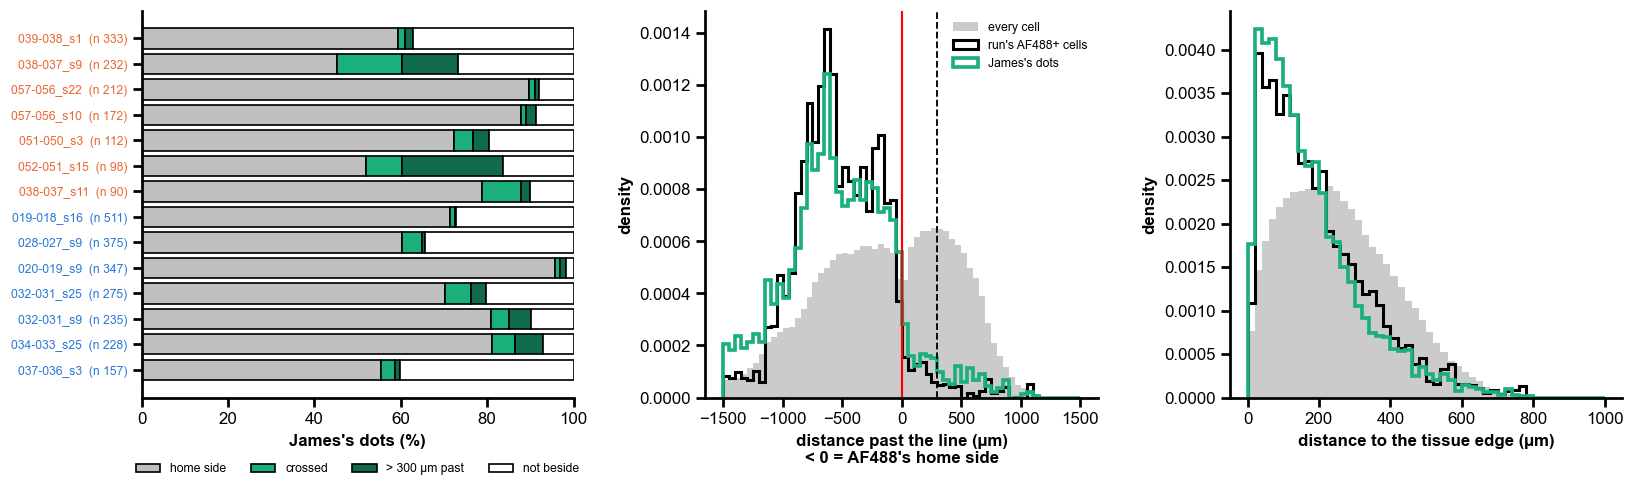

In [2]:
# ---------------------------------------------------------------- Settings: change these
LINE_BINS = np.arange(-1500, 1501, 50)     # µm past the line, for the left histogram
EDGE_BINS = np.arange(0, 1001, 20)         # µm to the tissue edge, for the right one
PLACE_COLOURS = {"home side": "#bfbfbf", "crossed": HAND_COLOUR, "> 300 µm past": "#0f6b4a", "not beside": "white"}
# ----------------------------------------------------------------------------------------


def place_of(away, beside):
    """Where a dot or cell lies against the run's line: home side / crossed / > 300 µm past / not beside."""
    away, beside = np.asarray(away, float), np.asarray(beside, bool)
    return np.select([~beside, away <= GAP_UM, away <= NEAR_UM], ["not beside", "home side", "crossed"],
                     "> 300 µm past")


clicks["place"] = place_of(clicks["away"], clicks["beside"])
where = []
for name, s in sections.iterrows():
    d = clicks[clicks["name"] == name]
    where.append({"section": short(name), "Genotype": s["Genotype"], "dots": len(d),
                  "on a cell": d["matched"].mean(), "in junction region": d["region"].mean(),
                  **{place: (d["place"] == place).mean() for place in PLACE_COLOURS},
                  "past the line, median (µm)": d.loc[d["beside"], "away"].median(),
                  "to the edge, median (µm)": d["edge"].median()})
where = pd.DataFrame(where).set_index("section")
total = {"Genotype": "all", "dots": len(clicks), "on a cell": clicks["matched"].mean(),
         "in junction region": clicks["region"].mean(),
         **{place: (clicks["place"] == place).mean() for place in PLACE_COLOURS},
         "past the line, median (µm)": clicks.loc[clicks["beside"], "away"].median(),
         "to the edge, median (µm)": clicks["edge"].median()}
where.loc["all 14"] = total
shares = ["on a cell", "in junction region", *PLACE_COLOURS]
display(where.assign(**{c: (where[c] * 100).round(0) for c in shares}).rename(columns={c: f"{c} (%)" for c in shares})
        .round(0))

# The dots against every cell of the same sections, and against the run's AF488+ cells.
every = pd.concat([c[["away", "beside", "edge"]] for c in cells.values()], ignore_index=True)
run_positive = pd.concat([c.loc[c[f"{CHANNEL} positive"], ["away", "beside", "edge"]] for c in cells.values()],
                         ignore_index=True)
references = {"every cell": every, "the run's AF488+ cells": run_positive}
rows = []
for measure, column, beside_only in (("past the line (µm, beside it)", "away", True),
                                     ("to the tissue edge (µm)", "edge", False)):
    a = clicks.loc[clicks["beside"] | (not beside_only), column].dropna()
    row = {"measure": measure, "James's dots, median": a.median(), "n dots": len(a)}
    for ref_name, ref in references.items():
        b = ref.loc[ref["beside"] | (not beside_only), column].dropna()
        row[f"{ref_name}, median"] = b.median()
        row[f"p vs {ref_name}"] = stats.mannwhitneyu(a, b).pvalue
    rows.append(row)
distance_table = pd.DataFrame(rows).set_index("measure")
display(distance_table.round(0).assign(**{c: distance_table[c].map("{:.1e}".format)
                                          for c in distance_table.columns if c.startswith("p ")}))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
ax = axes[0]
order = where.drop(index="all 14").sort_values(["Genotype", "dots"], ascending=[False, True])
left = np.zeros(len(order))
for place, colour in PLACE_COLOURS.items():
    ax.barh(range(len(order)), order[place] * 100, left=left, color=colour, label=place, **EDGE)
    left += order[place].to_numpy() * 100
ax.set_yticks(range(len(order)), [f"{i}  (n {int(n)})" for i, n in zip(order.index, order["dots"])], fontsize=8)
for tick, g in zip(ax.get_yticklabels(), order["Genotype"]):
    tick.set_color(GENOTYPE_COLOURS[g])
ax.set_xlim(0, 100)
ax.set_xlabel("James's dots (%)")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)
ax = axes[1]
for frame, label, style in ((every[every["beside"]], "every cell", dict(color="#bfbfbf", alpha=0.8)),
                            (run_positive[run_positive["beside"]], "run's AF488+ cells",
                             dict(histtype="step", color="black", linewidth=2)),
                            (clicks[clicks["beside"]], "James's dots", dict(histtype="step", color=HAND_COLOUR,
                                                                            linewidth=2.4))):
    ax.hist(frame["away"], bins=LINE_BINS, density=True, label=label, **style)
ax.axvline(0, color="red", lw=1.4)
ax.axvline(NEAR_UM, color="black", lw=1.2, ls="--")
ax.set_xlabel("distance past the line (µm)\n< 0 = AF488's home side")
ax.set_ylabel("density")
ax.legend(fontsize=8)
ax = axes[2]
for frame, label, style in ((every, "every cell", dict(color="#bfbfbf", alpha=0.8)),
                            (run_positive, "run's AF488+ cells", dict(histtype="step", color="black", linewidth=2)),
                            (clicks, "James's dots", dict(histtype="step", color=HAND_COLOUR, linewidth=2.4))):
    ax.hist(frame["edge"].clip(EDGE_BINS[0], EDGE_BINS[-1]), bins=EDGE_BINS, density=True, label=label, **style)
ax.set_xlabel("distance to the tissue edge (µm)")
ax.set_ylabel("density")
fig.tight_layout()
save(fig, "james_where")
plt.show()

## 2. Per section: James's count against each rule's

Per section, James's dots and each rule's AF488+ cells are counted in three zones:

- **whole section** — every dot, every segmented cell;
- **junction region** — the run's junction region (a dot by its own position, a cell by its centre);
- **crossed** — beside the line and 2–300 µm past it, the definition of 04.

The counts are plain numbers per section, not per mm: both sides of each comparison come from the same section, so the junction length cancels. Beside the nine rules, the **AF488 mask's own objects** (each connected piece of the mask, no Cellpose; 04, section 8c) are counted in the same zones, from each object's centre.

Per zone and method, over the 14 sections:

- **Spearman ρ** — do the two rank the sections the same way? The minimum for a usable stand-in.
- **Lin's CCC** — do they give the *same number*? 1 only when the dots lie on the 1 : 1 line; a rule that ranks well but counts twice as many gets a low CCC.
- **R² and slope** of the least-squares line (method against James), as 04 section 8d. Slope 1 = each extra cell James counts is one extra cell for the rule.
- **method ÷ James, median** — the level: 1 = the same count, 2 = the rule counts twice as many (sections where James has 0 left out).

**How to read the figures:** one panel per method, one dot per section coloured by genotype. x = James's count, y = the method's, both in the same zone; the dashed line is 1 : 1, the solid one the least-squares fit. Dots along a line parallel to 1 : 1 rank the sections alike at a different level (fixable by the threshold); a shapeless cloud means the method measures something else. Each panel has its own y axis. With 14 sections one big section weighs a lot in every R²: read "follows / does not follow", not a ranking to the second decimal.

In [3]:
# ---------------------------------------------------------------- Settings: change these
MASKS = OUT / "af488_mask"                 # af488_masks.py: per section, the mask's objects
MASK_LEVELS = ("kmad3", "kmad5", "kmad8")
ZONES = ["whole section", "junction region", "crossed"]
# ----------------------------------------------------------------------------------------
OBJECT_NAMES = [f"AF488 mask objects · {m[4:]} SD" for m in MASK_LEVELS]
METHODS = RULE_NAMES + OBJECT_NAMES


def in_zone(frame, zone):
    """Which rows (cells, dots or mask objects with columns region / beside / away) lie in *zone*."""
    if zone == "whole section":
        return np.ones(len(frame), bool)
    if zone == "junction region":
        return frame["region"].to_numpy(bool)
    away = frame["away"].to_numpy(float)
    return frame["beside"].to_numpy(bool) & (away > GAP_UM) & (away <= NEAR_UM)


def ccc(a, b):
    """Lin's concordance correlation coefficient (as validation/count_common.py)."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    ok = np.isfinite(a) & np.isfinite(b)
    a, b = a[ok], b[ok]
    if len(a) < 3:
        return np.nan
    return 2 * np.cov(a, b, bias=True)[0, 1] / (a.var() + b.var() + (a.mean() - b.mean()) ** 2)


# Each rule's calls on every cell, once.
calls = {(name, rule): positive(cells[name], rule) for name in names for rule in RULE_NAMES}

# The mask's own objects, with the columns in_zone needs.
objects = {}
for name in names:
    target = MASKS / name / "objects.parquet"
    o = pd.read_parquet(target) if target.exists() else pd.DataFrame(columns=["mask"])
    objects[name] = pd.DataFrame({
        "mask": o["mask"].to_numpy(),
        "region": o.get("In region", pd.Series(False, index=o.index)).fillna(False).to_numpy(bool),
        "beside": o.get("Beside the junction line", pd.Series(False, index=o.index)).fillna(False).to_numpy(bool),
        "away": o.get("Distance to the junction line (µm)", pd.Series(np.nan, index=o.index)).to_numpy(float)
                * sections.at[name, "sign"]})
missing = [short(n) for n in names if not (MASKS / n / "objects.parquet").exists()]
print("sections without mask objects:", ", ".join(missing) if missing else "none")

count_rows = []
for name in names:
    c, d, o = cells[name], clicks[clicks["name"] == name], objects[name]
    for zone in ZONES:
        here = in_zone(c, zone)
        row = {"name": name, "Genotype": sections.at[name, "Genotype"], "zone": zone,
               "James": int(in_zone(d, zone).sum())}
        row.update({rule: int((calls[name, rule] & here).sum()) for rule in RULE_NAMES})
        o_here = in_zone(o, zone)
        row.update({label: int((o_here & (o["mask"] == m).to_numpy()).sum()) for label, m in zip(OBJECT_NAMES, MASK_LEVELS)})
        count_rows.append(row)
counts = pd.DataFrame(count_rows)


def agreement_of(x, y):
    """Per-section agreement of a method's counts *y* with James's *x*."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    fit = stats.linregress(x, y) if np.ptp(x) > 0 else None
    ok = x > 0
    return {"James, median": np.median(x), "method, median": np.median(y),
            "Spearman ρ": stats.spearmanr(x, y).statistic, "CCC": ccc(x, y),
            "R²": fit.rvalue ** 2 if fit else np.nan, "slope": fit.slope if fit else np.nan,
            "intercept": fit.intercept if fit else np.nan,
            "method ÷ James, median": float(np.median(y[ok] / x[ok])) if ok.any() else np.nan}


agreement = pd.DataFrame([{"zone": zone, "method": method, **agreement_of(g["James"], g[method])}
                          for zone, g in counts.groupby("zone", sort=False) for method in METHODS]
                         ).set_index(["zone", "method"])
display(agreement.round(2))

# Compact: one column per zone.
compact = agreement[["Spearman ρ", "CCC", "R²", "method ÷ James, median"]].unstack("zone")
compact = compact.reindex(METHODS).reindex(columns=ZONES, level=1)
display(compact.round(2))
print("James's count per section (whole section / junction region / crossed):")
display(counts.pivot(index="name", columns="zone", values="James")[ZONES].rename(index=short)
        .join(sections["Genotype"].rename(index=short)))

sections without mask objects: none


James, median  method, median  Spearman ρ   CCC    R²  slope  intercept  method ÷ James, median
zone            method                                                                                                                              
whole section   raw · median + 3 SD                          230.0          1439.5        0.70  0.04  0.34  11.21    -758.10                    5.76
                raw · median + 5 SD                          230.0           193.5        0.61  0.08  0.26   5.31    -482.19                    1.48
                raw · median + 7 SD                          230.0            88.5        0.57  0.13  0.21   3.03    -303.27                    0.69
                median filter · median + 3 SD                230.0          1070.0        0.85  0.09  0.75   7.57    -455.51                    5.47
                median filter · median + 5 SD                230.0           638.0        0.91  0.17  0.56   3.98    -254.56                    2.66
                median filter · median + 7 SD (run)          230.0           434.0        0.93  0.25  0.43   2.60    -158.68                    1.49
                AF488 mask · 3 SD                            230.0           618.0        0.87  0.13  0.82   7.64    -789.98                    3.05
                AF488 mask · 5 SD                            230.0           307.0        0.92  0.28  0.62   3.44    -336.70                    1.45
                AF488 mask · 8 SD                            230.0           183.0        0.92  0.40  0.40   1.76    -157.84                    0.78
                AF488 mask objects · 3 SD                    230.0           366.5        0.87  0.41  0.87   2.46    -118.73                    1.88
                AF488 mask objects · 5 SD                    230.0           205.0        0.89  0.85  0.88   1.44     -84.13                    0.90
                AF488 mask objects · 8 SD                    230.0           135.0        0.92  0.63  0.72   0.78     -37.06                    0.53
junction region raw · median + 3 SD                            8.0            87.0        0.12  0.00  0.00   0.29     121.35                    5.94
                raw · median + 5 SD                            8.0             4.5        0.59 -0.04  0.01  -0.28      24.45                    0.60
                raw · median + 7 SD                            8.0             2.0        0.35 -0.00  0.00  -0.00       6.95                    0.21
                median filter · median + 3 SD                  8.0            70.5        0.40  0.06  0.15   1.77      61.68                    7.56
                median filter · median + 5 SD                  8.0            21.0        0.54  0.29  0.26   1.02      16.16                    2.84
                median filter · median + 7 SD (run)            8.0             9.0        0.69  0.39  0.17   0.55       7.78                    1.14
                AF488 mask · 3 SD                              8.0            57.5        0.24  0.05  0.08   1.51      55.88                    4.99
                AF488 mask · 5 SD                              8.0            12.5        0.48  0.41  0.24   0.76       9.09                    1.81
                AF488 mask · 8 SD                              8.0             4.0        0.40  0.34  0.15   0.31       3.25                    0.53
                AF488 mask objects · 3 SD                      8.0            33.0        0.29  0.18  0.19   0.85      25.83                    2.87
                AF488 mask objects · 5 SD                      8.0            10.0        0.60  0.57  0.36   0.45       6.01                    1.44
                AF488 mask objects · 8 SD                      8.0             3.5        0.53  0.36  0.34   0.29       1.83                    0.38
crossed         raw · median + 3 SD                            7.0            85.0        0.15  0.00  0.00   0.07     121.04                    6.98
                raw · median +

Spearman ρ                                   CCC                                    R²                         method ÷ James, median                        
zone                                whole section junction region crossed whole section junction region crossed whole section junction region crossed          whole section junction region crossed
method                                                                                                                                                                                              
raw · median + 3 SD                          0.70            0.12    0.15          0.04            0.00    0.00          0.34            0.00    0.00                   5.76            5.94    6.98
raw · median + 5 SD                          0.61            0.59    0.64          0.08           -0.04   -0.02          0.26            0.01    0.00                   1.48            0.60    0.69
raw · median + 7 SD                          0.57            0.35    0.40          0.13           -0.00    0.01          0.21            0.00    0.00                   0.69            0.21    0.20
median filter · median + 3 SD                0.85            0.40    0.37          0.09            0.06    0.04          0.75            0.15    0.11                   5.47            7.56    7.78
median filter · median + 5 SD                0.91            0.54    0.53          0.17            0.29    0.25          0.56            0.26    0.27                   2.66            2.84    2.85
median filter · median + 7 SD (run)          0.93            0.69    0.69          0.25            0.39    0.38          0.43            0.17    0.19                   1.49            1.14    1.25
AF488 mask · 3 SD                            0.87            0.24    0.14          0.13            0.05    0.03          0.82            0.08    0.05                   3.05            4.99    5.67
AF488 mask · 5 SD                            0.92            0.48    0.42          0.28            0.41    0.35          0.62            0.24    0.23                   1.45            1.81    1.70
AF488 mask · 8 SD                            0.92            0.40    0.34          0.40            0.34    0.37          0.40            0.15    0.16                   0.78            0.53    0.55
AF488 mask objects · 3 SD                    0.87            0.29    0.17          0.41            0.18    0.15          0.87            0.19    0.15                   1.88            2.87    2.81
AF488 mask objects · 5 SD                    0.89            0.60    0.47          0.85            0.57    0.58          0.88            0.36    0.35                   0.90            1.44    1.35
AF488 mask objects · 8 SD                    0.92            0.53    0.33          0.63            0.36    0.30          0.72            0.34    0.17                   0.53            0.38    0.50

James's count per section (whole section / junction region / crossed):


,whole section,junction region,crossed,Genotype
name,,,,
019-018_s16,511,7,6,WT3
020-019_s9,347,5,4,WT3
028-027_s9,375,18,17,WT3
032-031_s25,275,23,17,WT3
032-031_s9,235,12,10,WT3
034-033_s25,228,15,12,WT3
037-036_s3,157,8,5,WT3
038-037_s11,90,8,8,GD1
038-037_s9,232,47,35,GD1


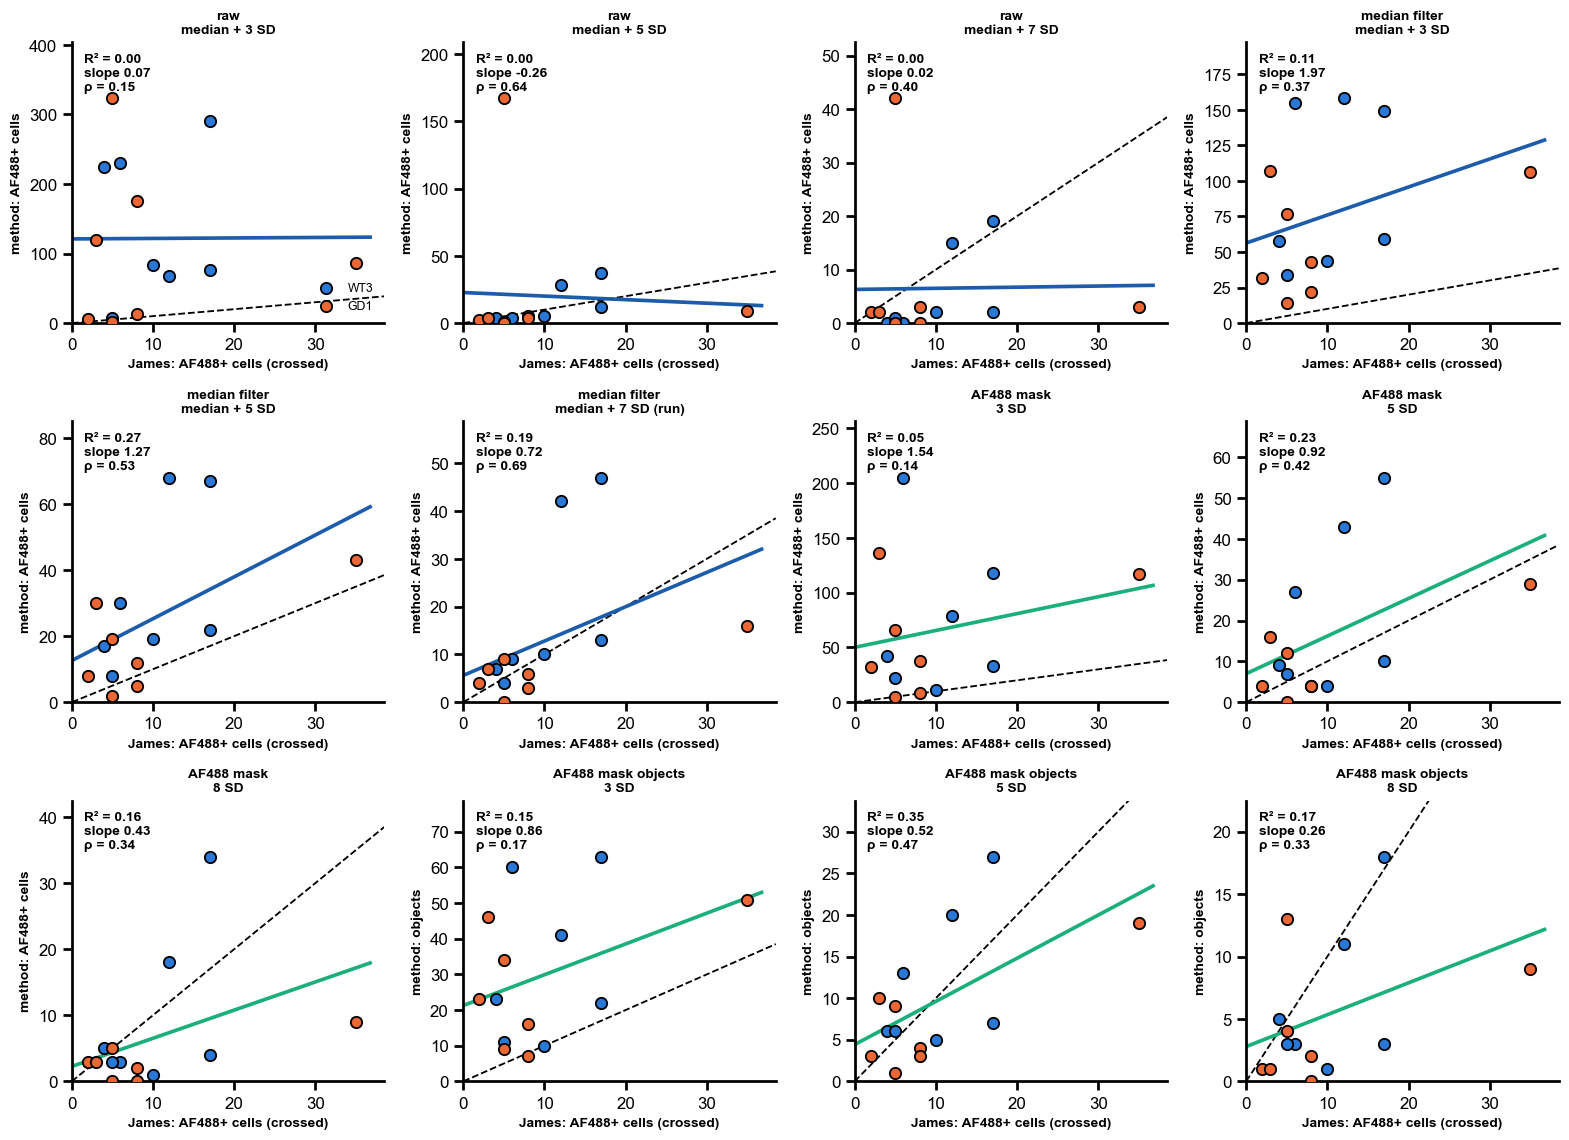

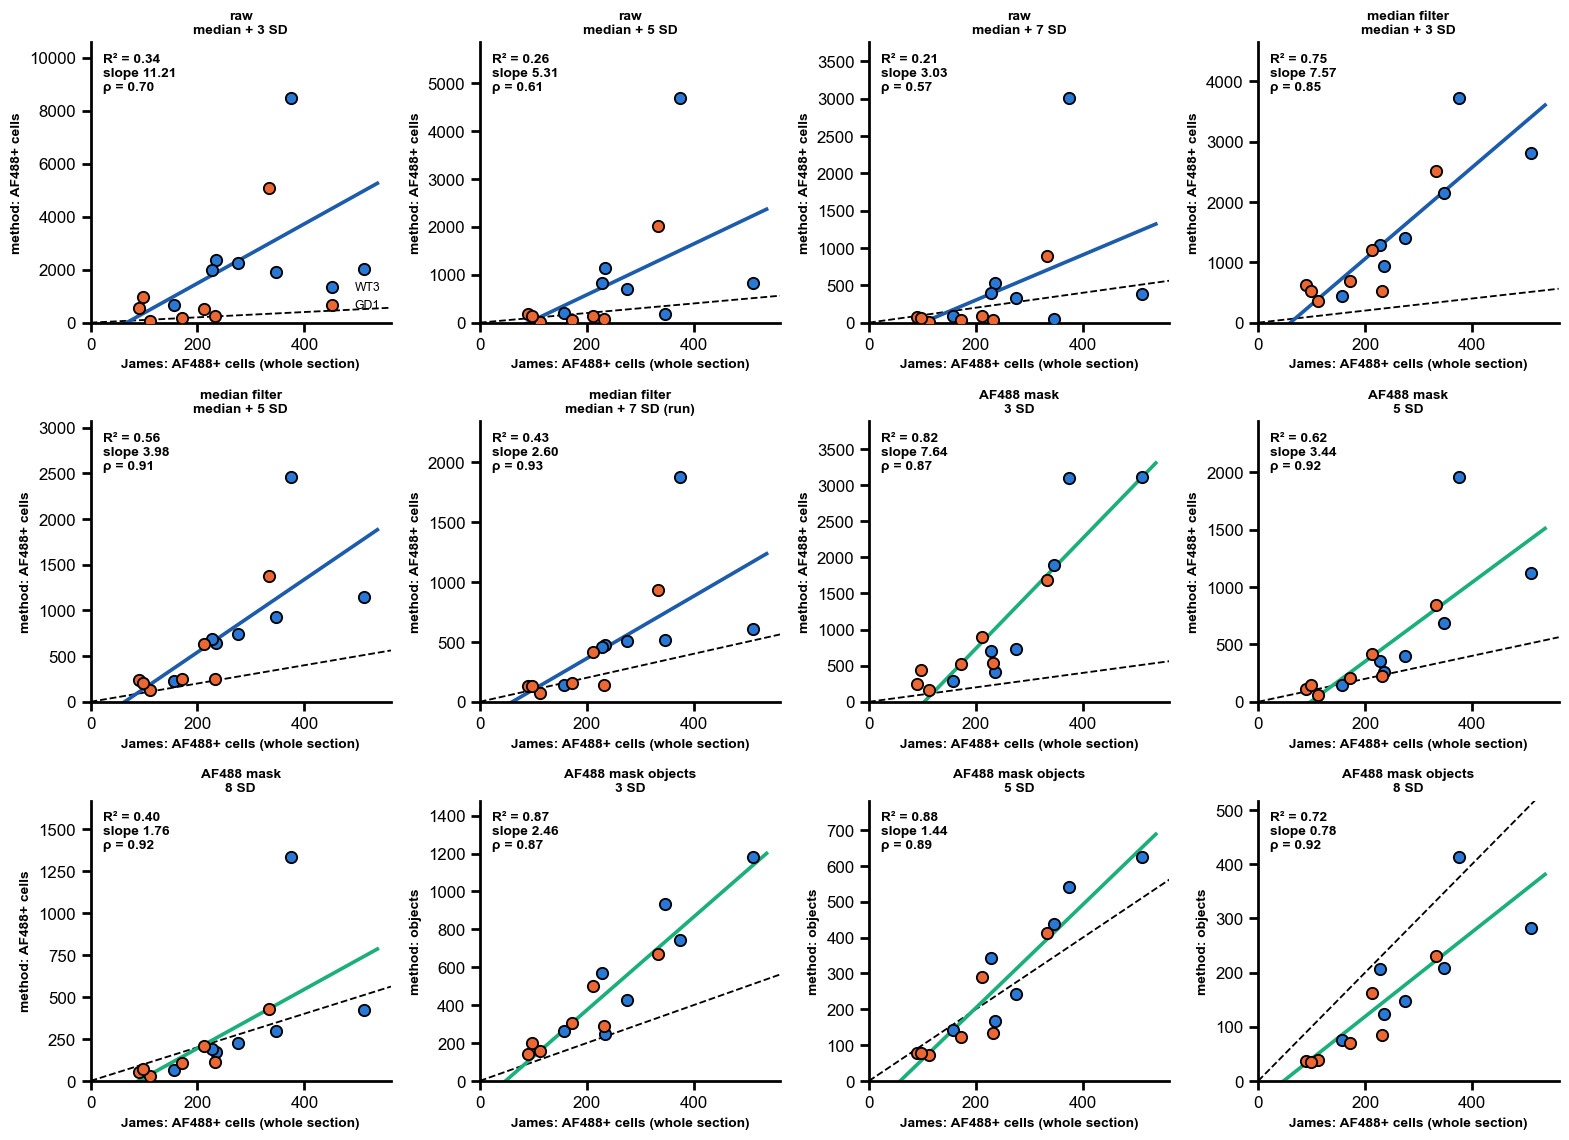

In [4]:
# ---------------------------------------------------------------- Settings: change these
GRID_ZONES = {"crossed": "james_vs_methods_crossed", "whole section": "james_vs_methods_section"}  # zone: figure name
COLUMNS = 4
# ----------------------------------------------------------------------------------------


def method_grid(zone):
    """One panel per method: James's count (x) against the method's (y), one dot per section, in *zone*."""
    g = counts[counts["zone"] == zone]
    x = g["James"].to_numpy(float)
    rows = int(np.ceil(len(METHODS) / COLUMNS))
    fig, axes = plt.subplots(rows, COLUMNS, figsize=(3.6 * COLUMNS, 3.5 * rows), squeeze=False)
    for ax, method in zip(axes.flat, METHODS):
        y = g[method].to_numpy(float)
        a = agreement.loc[(zone, method)]
        right, top = max(x.max(), 1) * 1.1, max(y.max(), 1) * 1.25
        ax.plot([0, min(right, top)], [0, min(right, top)], color="black", lw=1.2, ls="--", zorder=1)
        if np.isfinite(a["slope"]):
            xs = np.array([0, x.max() * 1.05])
            ax.plot(xs, a["intercept"] + a["slope"] * xs, color="#1c5cab" if "mask" not in method else HAND_COLOUR,
                    lw=2.4, zorder=2)
        for genotype in GENOTYPES:
            here = g["Genotype"].to_numpy() == genotype
            ax.scatter(x[here], y[here], s=55, color=GENOTYPE_COLOURS[genotype], zorder=3, label=genotype,
                       edgecolor="black", linewidth=1.2)
        ax.text(0.04, 0.96, f"R² = {a['R²']:.2f}\nslope {a['slope']:.2f}\nρ = {a['Spearman ρ']:.2f}",
                transform=ax.transAxes, va="top", fontsize=9, fontweight="bold")
        ax.set_xlim(0, right)
        ax.set_ylim(0, top)
        ax.set_title(method.replace(" · ", "\n"), fontsize=9)
        ax.set_xlabel(f"James: AF488+ cells ({zone})", fontsize=9)
        ax.set_ylabel("method: objects" if "objects" in method else "method: AF488+ cells", fontsize=9)
    for ax in list(axes.flat)[len(METHODS):]:
        ax.axis("off")
    axes[0, 0].legend(fontsize=8, loc="lower right")
    fig.tight_layout()
    return fig


for zone, figure_name in GRID_ZONES.items():
    fig = method_grid(zone)
    save(fig, figure_name)
    plt.show()

## 3. Cell by cell: which cells both call positive

Per rule and zone, pooled over the 14 sections:

- **TP** — cells in the zone the rule calls positive and James put a dot on;
- **FP** — cells in the zone the rule calls positive and James did not dot;
- **FN** — James's dots in the zone the rule does not call: dotted cells called negative, plus dots with no segmented cell within 7 µm (those no rule can find).

A cell is in a zone by its own centre, a dot by its own position. **Precision** = TP / (TP + FP): of the rule's positives, the share James dotted. **Recall** = TP / (TP + FN): of James's dots, the share the rule finds. **F1** is their harmonic mean; **F1 per section, median** gives each section the same weight. The **ceiling** is the share of dots in the zone with a segmented cell under them: the most recall any rule can reach. The mask's own objects are left out here: an object is not a cell, so it cannot be matched one to one.

**Read precision as a lower bound.** James may have missed labelled cells, and a positive cell he did not dot counts as an FP here. A low precision may be cells he missed rather than cells the rule invents; only a look at a few FPs on the images can tell (section 7). Recall is the safer number: a cell he dotted that the rule calls negative is a real disagreement (or a dot on the wrong nucleus).

**How to read the figure:** one panel per zone, one dot per rule (shape = the value it thresholds, the number = k). Up and to the right is better; the grey curves are equal F1 (0.2, 0.4, 0.6, 0.8). The dashed vertical line is the ceiling on recall.

,dots,dots on a cell,ceiling on recall
zone,,,
whole section,3377,2988,0.884809
junction region,169,154,0.911243
crossed,137,129,0.941606


TP     FP    FN  precision  recall    F1  F1 per section, median
zone            rule                                                                                                   
whole section   raw · median + 3 SD                  1776  25467  1601       0.07    0.53  0.12                    0.15
                raw · median + 5 SD                  1339   9835  2038       0.12    0.40  0.18                    0.22
                raw · median + 7 SD                  1068   4912  2309       0.18    0.32  0.23                    0.22
                median filter · median + 3 SD        2720  16472   657       0.14    0.81  0.24                    0.25
                median filter · median + 5 SD        2304   7589  1073       0.23    0.68  0.35                    0.37
                median filter · median + 7 SD (run)  1881   4669  1496       0.29    0.56  0.38                    0.40
                AF488 mask · 3 SD                    2476  12256   901       0.17    0.73  0.27                    0.32
                AF488 mask · 5 SD                    1988   4921  1389       0.29    0.59  0.39                    0.41
                AF488 mask · 8 SD                    1343   2385  2034       0.36    0.40  0.38                    0.37
junction region raw · median + 3 SD                    79   1669    91       0.05    0.46  0.08                    0.07
                raw · median + 5 SD                    51    244   119       0.17    0.30  0.22                    0.25
                raw · median + 7 SD                    32     65   138       0.33    0.19  0.24                    0.13
                median filter · median + 3 SD         126   1036    44       0.11    0.74  0.19                    0.18
                median filter · median + 5 SD         101    297    69       0.25    0.59  0.36                    0.37
                median filter · median + 7 SD (run)    70    132   100       0.35    0.41  0.38                    0.34
                AF488 mask · 3 SD                     113    924    57       0.11    0.66  0.19                    0.21
                AF488 mask · 5 SD                      76    179    94       0.30    0.45  0.36                    0.34
                AF488 mask · 8 SD                      46     52   124       0.47    0.27  0.34                    0.30
crossed         raw · median + 3 SD                    70   1634    67       0.04    0.51  0.08                    0.07
                raw · median + 5 SD                    45    237    92       0.16    0.33  0.21                    0.27
                raw · median + 7 SD                    29     62   108       0.32    0.21  0.25                    0.12
                median filter · median + 3 SD         106    952    31       0.10    0.77  0.18                    0.20
                median filter · median + 5 SD          86    264    51       0.25    0.63  0.35                    0.38
                median filter · median + 7 SD (run)    62    115    75       0.35    0.45  0.39                    0.34
                AF488 mask · 3 SD                      98    814    39       0.11    0.72  0.19                    0.22
                AF488 mask · 5 SD                      64    160    73       0.29    0.47  0.35                    0.36
                AF488 mask · 8 SD                      40     50    97       0.44    0.29  0.35                    0.24

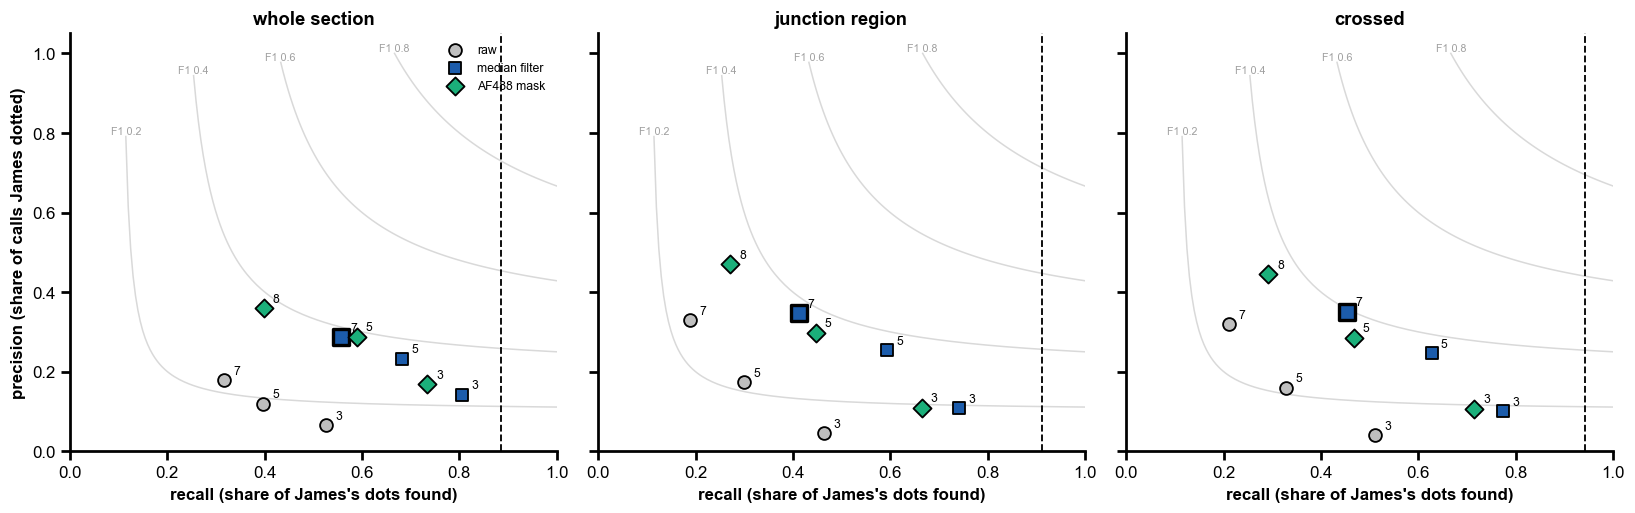

In [5]:
# ---------------------------------------------------------------- Settings: change these
FAMILY_MARKERS = {"raw": "o", "median filter": "s", "AF488 mask": "D"}   # by the value a rule thresholds
FAMILY_COLOURS = {"raw": "#bfbfbf", "median filter": "#1c5cab", "AF488 mask": HAND_COLOUR}
# ----------------------------------------------------------------------------------------

tally_rows = []
for name in names:
    c, d = cells[name], clicks[clicks["name"] == name]
    clicked = c["clicked"].to_numpy(bool)
    for zone in ZONES:
        here, d_here = in_zone(c, zone), in_zone(d, zone)
        unmatched = int((d_here & ~d["matched"].to_numpy(bool)).sum())
        for rule in RULE_NAMES:
            called = calls[name, rule] & here
            tp = int((called & clicked).sum())
            tally_rows.append({"name": name, "zone": zone, "rule": rule, "dots": int(d_here.sum()),
                               "dots on a cell": int((d_here & d["matched"].to_numpy(bool)).sum()),
                               "TP": tp, "FP": int(called.sum()) - tp,
                               "FN": int((clicked & here & ~called).sum()) + unmatched})
tally = pd.DataFrame(tally_rows)


def prf(t):
    """Pooled TP / FP / FN, precision, recall, F1, and the per-section median F1."""
    tp, fp, fn = t["TP"].sum(), t["FP"].sum(), t["FN"].sum()
    precision, recall = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    per = 2 * t["TP"] / (2 * t["TP"] + t["FP"] + t["FN"]).replace(0, np.nan)
    return pd.Series({"TP": tp, "FP": fp, "FN": fn, "precision": precision, "recall": recall,
                      "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
                      "F1 per section, median": per.median()})


cell_by_cell = tally.groupby(["zone", "rule"], sort=False).apply(prf)
ceiling = (tally.drop_duplicates(["name", "zone"]).groupby("zone")[["dots", "dots on a cell"]].sum())
ceiling["ceiling on recall"] = ceiling["dots on a cell"] / ceiling["dots"]
display(ceiling.loc[ZONES])
display(cell_by_cell.astype({"TP": int, "FP": int, "FN": int}).round(2))

fig, axes = plt.subplots(1, len(ZONES), figsize=(5 * len(ZONES), 4.8), sharex=True, sharey=True)
grid = np.linspace(0.01, 1, 200)
for ax, zone in zip(axes, ZONES):
    for f1 in (0.2, 0.4, 0.6, 0.8):
        p = f1 * grid / (2 * grid - f1)
        ok = (p > 0) & (p <= 1)
        ax.plot(grid[ok], p[ok], color="#d9d9d9", lw=1, zorder=0)
        ax.text(grid[ok][0], min(p[ok][0], 1.0), f"F1 {f1:g}", color="#a0a0a0", fontsize=7, ha="center", va="bottom")
    ax.axvline(ceiling.at[zone, "ceiling on recall"], color="black", lw=1.2, ls="--")
    for rule in RULE_NAMES:
        family = rule.split(" · ")[0]
        k = rule.split(" · ")[1].split(" SD")[0].replace("median + ", "")
        r = cell_by_cell.loc[(zone, rule)]
        ax.scatter(r["recall"], r["precision"], s=120 if rule == RUN_RULE else 70, marker=FAMILY_MARKERS[family],
                   color=FAMILY_COLOURS[family], edgecolor="black", linewidth=2.2 if rule == RUN_RULE else 1.2,
                   zorder=3, label=family if k.startswith("3") else None)
        ax.annotate(k, (r["recall"], r["precision"]), xytext=(6, 4), textcoords="offset points", fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.set_title(zone)
    ax.set_xlabel("recall (share of James's dots found)")
axes[0].set_ylabel("precision (share of calls James dotted)")
axes[0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
save(fig, "james_precision_recall")
plt.show()

## 4. The outcomes per section, James and every rule

**Question.** James's dots are one more way of saying which cells are AF488+. Do they lead to the same biology as the rules: more AF488+ cells in WT3, crossed cells nearer the organoid edge in WT3, and so on?

**James as a method.** For his dots no rule is applied: every dot is an AF488+ cell. Each dot is placed against the run's junction line exactly as the cells are (`james_clicks.py`): in the junction region or not, distance past the line (`away`, + = into the organoid where AF488 is not at home), beside the line or past its ends, distance to the tissue edge (that of the nearest segmented cell). The distance outcomes use the dots' own positions, so a dot that matched no segmented cell still counts.

**The outcomes** are 04's, per section (one dot per section in every graph):

| outcome | what it is |
|---|---|
| cells in whole section | every AF488+ cell of the section. James counted the whole section, so this is his most complete number |
| cells at home | beside the line, more than 2 µm on AF488's own side (most of the whole section) |
| crossed cells / per mm | AF488+ cells 2–300 µm past the line, beside it; per mm of junction line |
| cells in junction / per mm | AF488+ cells in the junction region |
| crossed: distance to edge, past the line (µm, ÷ assembloid length, ÷ AF488+ centroid), edge vs line slope, edge ÷ local half-width | as 04, from sections with at least `MIN_EDGE` crossed cells. The half-width is worked out from **all** cells of the section, whichever method calls the positives |

The rules' bars are set, as in 04, by the junction region's cells and then applied to every cell of the section.

**How to read it.** The first table puts James's counts beside the run's rule and the AF488 mask (5 SD), section by section. The second table gives the median section per genotype for every method and outcome. Look at whether James's WT3 row is above his GD1 row where the rules' are.

In [6]:
WIDTH_BIN_UM = 25.0      # the organoid's half-width is taken in steps of this much past the line (as 04)
WIDTH_MIN_CELLS = 20     # a step with fewer cells than this has no half-width
WIDTH_EDGES = np.arange(0, NEAR_UM + WIDTH_BIN_UM, WIDTH_BIN_UM)
HAND = "James (by hand)"                 # James's dots, as one more method
METHODS = [HAND, *RULE_NAMES]


def half_widths(away, beside, edge):
    """Per 25 µm step past the line: how deep the middle of the tissue lies there
    (the 99th percentile of every beside cell's distance to the edge in that step; NaN for a thin step)."""
    step = np.digitize(away, WIDTH_EDGES) - 1
    out = np.full(len(WIDTH_EDGES) - 1, np.nan)
    for k in range(len(out)):
        here = beside & (step == k) & (edge > 0)
        if here.sum() >= WIDTH_MIN_CELLS:
            out[k] = np.percentile(edge[here], 99)
    return out


def width_at(away, widths):
    """The half-width at each distance past the line (NaN outside 0–NEAR_UM or in a thin step)."""
    step = np.digitize(away, WIDTH_EDGES) - 1
    ok = (step >= 0) & (step < len(widths))
    out = np.full(len(away), np.nan)
    out[ok] = widths[step[ok]]
    return out


def section_outcomes(s, found, widths):
    """04's outcomes for one section, from the AF488+ things *found* (cells a rule calls, or James's dots):
    a table with their `away`, `beside`, `edge` and `region`. *widths* = the section's half-widths (all its cells)."""
    away, beside = found["away"].to_numpy(float), found["beside"].to_numpy(bool)
    edge, region = found["edge"].to_numpy(float), found["region"].to_numpy(bool)
    crossed = beside & (away > GAP_UM) & (away <= NEAR_UM)
    n_crossed = int(crossed.sum())
    depth, side = away[crossed], edge[crossed]
    relative = np.clip(side / width_at(depth, widths), 0, 1)
    enough = n_crossed >= MIN_EDGE
    return {
        "cells in whole section": len(found),
        "cells at home": int((beside & (away < -GAP_UM)).sum()),
        "crossed cells": n_crossed,
        "crossed per mm": n_crossed / s["length (mm)"],
        "cells in junction": int(region.sum()),
        "in junction per mm": int(region.sum()) / s["length (mm)"],
        "crossed: mean distance to edge (µm)": side.mean() if enough else np.nan,
        "crossed: mean distance past line (µm)": depth.mean() if enough else np.nan,
        **{f"crossed: distance past line ÷ {scale}": depth.mean() / s[column] if enough else np.nan
           for scale, column in SCALES.items()},
        "crossed: edge vs line slope": np.polyfit(depth, side, 1)[0] if enough and np.ptp(depth) > 0 else np.nan,
        "crossed: edge ÷ local half-width": np.nanmean(relative) if np.isfinite(relative).sum() >= MIN_EDGE else np.nan,
    }


PLACE = ["away", "beside", "edge", "region"]
records = []
for name, s in sections.iterrows():
    c = cells[name]
    widths = half_widths(c["away"].to_numpy(float), c["beside"].to_numpy(bool), c["edge"].to_numpy(float))
    who = {"name": name, "Genotype": s["Genotype"], "Experiment": s["Experiment"], "slide": s["slide"]}
    records.append({**who, "method": HAND, **section_outcomes(s, clicks.loc[clicks["name"] == name, PLACE], widths)})
    for rule in RULE_NAMES:
        records.append({**who, "method": rule, **section_outcomes(s, c.loc[positive(c, rule), PLACE], widths)})
obs14 = pd.DataFrame(records)
print(f"{len(obs14)} rows: {len(sections)} sections × {len(METHODS)} methods (James + {len(RULE_NAMES)} rules)")

140 rows: 14 sections × 10 methods (James + 9 rules)


In [7]:
OUTCOMES14 = {  # outcome → ("fold" for counts, "difference" for µm or slope), axis label — 04's, plus the whole section
    "cells in whole section": ("fold", "AF488+ cells in the\nwhole section"),
    "cells at home": ("fold", "AF488+ cells at home\n(beside the line, home side)"),
    "crossed cells": ("fold", "AF488+ cells that crossed\n(per section)"),
    "crossed per mm": ("fold", "AF488+ cells that crossed\n(per mm of junction)"),
    "cells in junction": ("fold", "AF488+ cells in the junction region\n(per section)"),
    "in junction per mm": ("fold", "AF488+ cells in the junction region\n(per mm of junction)"),
    "crossed: mean distance to edge (µm)": ("difference", "crossed cells: mean distance\nto the organoid edge (µm)"),
    "crossed: mean distance past line (µm)": ("difference", "crossed cells: mean distance\npast the line (µm)"),
    **{f"crossed: distance past line ÷ {scale}": ("difference", f"crossed cells: mean distance past\nthe line ÷ {scale}")
       for scale in SCALES},
    "crossed: edge vs line slope": ("difference", "crossed cells: µm further from the edge\nper µm further past the line"),
    "crossed: edge ÷ local half-width": ("difference", "crossed cells: distance to the edge\n÷ organoid half-width there"),
}
SHOWN = [HAND, RUN_RULE, "AF488 mask · 5 SD"]       # the methods drawn side by side below

# Per section: James beside the run's rule and the mask at 5 SD, for the counts.
count_columns = ["cells in whole section", "cells at home", "cells in junction", "crossed cells"]
per_section = (obs14[obs14["method"].isin(SHOWN)]
               .pivot(index="name", columns="method", values=count_columns)
               .reindex(columns=pd.MultiIndex.from_product([count_columns, SHOWN])))
per_section.index = [f"{sections.at[n, 'Genotype']} · {short(n)}" for n in per_section.index]
display(per_section.sort_index().round(0).astype("Int64"))

# Per genotype: the median section, every method and outcome.
genotype_medians = obs14.groupby(["method", "Genotype"])[list(OUTCOMES14)].median().reindex(
    pd.MultiIndex.from_product([METHODS, GENOTYPES]))
display(genotype_medians.round(2))

cells in whole section                                                         cells at home                                                       cells in junction  \
                         James (by hand) median filter · median + 7 SD (run) AF488 mask · 5 SD James (by hand) median filter · median + 7 SD (run) AF488 mask · 5 SD   James (by hand)   
GD1 · 038-037_s11                     90                                 135               112              71                                 116                98                 8   
GD1 · 038-037_s9                     232                                 144               221             105                                  88               126                47   
GD1 · 039-038_s1                     333                                 930               840             198                                 630               534                 5   
GD1 · 051-050_s3                     112                                  69                60              81                                  56                48                 5   
GD1 · 052-051_s15                     98                                 129               142              51                                 105               101                11   
GD1 · 057-056_s10                    172                                 157               203             151                                 146               183                 2   
GD1 · 057-056_s22                    212                                 415               417             190                                 343               324                 3   
WT3 · 019-018_s16                    511                                 610              1121             365                                 488               891                 7   
WT3 · 020-019_s9                     347                                 517               683             332                                 487               643                 5   
WT3 · 028-027_s9                     375                                1871              1954             226                                1176              1224                18   
WT3 · 032-031_s25                    275                                 506               400             193                                 433               354                23   
WT3 · 032-031_s9                     235                                 476               259             190                                 445               251                12   
WT3 · 034-033_s25                    228                                 453               355             185                                 356               285                15   
WT3 · 037-036_s3                     157                                 138               142              86                                  67                72                 8   

                                                                          crossed cells                                                        
                  median filter · median + 7 SD (run) AF488 mask · 5 SD James (by hand) median filter · median + 7 SD (run) AF488 mask · 5 SD  
GD1 · 038-037_s11                                   6                 4               8                                   6                 4  
GD1 · 038-037_s9                                   19                36              35                                  16                29  
GD1 · 039-038_s1                                    9                12               5                                   9                12  
GD1 · 051-050_s3                                    0                 0               5                                   0                 0  
GD1 · 052-051_s15                                   3                 4               8                                   3                 4  
GD1 · 057-056_s10                

cells in whole section  cells at home  crossed cells  crossed per mm  cells in junction  in junction per mm  crossed: mean distance to edge (µm)  \
James (by hand)                     WT3                   275.0          193.0           10.0           11.11               12.0               17.77                               241.56   
                                    GD1                   172.0          105.0            5.0            7.49                5.0                8.56                               205.15   
raw · median + 3 SD                 WT3                  2026.0         1628.0           83.0          153.46               81.0              149.76                               275.00   
                                    GD1                   524.0          198.0           87.0          119.49               93.0              119.49                               232.12   
raw · median + 5 SD                 WT3                   819.0          661.0            5.0            9.24                5.0                9.24                               298.62   
                                    GD1                   133.0           86.0            4.0            4.02                4.0                4.02                               241.22   
raw · median + 7 SD                 WT3                   379.0          315.0            2.0            2.31                2.0                3.70                               295.04   
                                    GD1                    62.0           59.0            2.0            2.01                2.0                2.01                               187.86   
median filter · median + 3 SD       WT3                  1395.0         1184.0           59.0           81.35               73.0              106.62                               257.82   
                                    GD1                   617.0          527.0           43.0           40.27               52.0               48.70                               241.43   
median filter · median + 5 SD       WT3                   738.0          633.0           22.0           25.42               31.0               35.82                               275.45   
                                    GD1                   250.0          205.0           12.0           19.44               12.0               19.44                               257.30   
median filter · median + 7 SD (run) WT3                   506.0          445.0           10.0           15.02               10.0               18.49                               279.74   
                                    GD1                   144.0          116.0            6.0            7.03                6.0                7.03                               262.96   
AF488 mask · 3 SD                   WT3                   737.0          647.0           42.0           48.87               74.0               62.65                               250.03   
                                    GD1                   522.0          230.0           38.0           35.59               46.0               43.08                               238.05   
AF488 mask · 5 SD                   WT3                   400.0          354.0           10.0           15.55               15.0               20.36                               273.88   
                                    GD1                   203.0          126.0            4.0            7.21                4.0                7.21                               238.62   
AF488 mask · 8 SD                   WT3                   228.0          206.0            4.0            4.62                5.0                5.78                               296.33   
                                    GD1                   104.0           76.0            3.0            3.01                3.0                3.01                               251.40   

                                         crossed: mean distance past li

## 5. WT3 against GD1, by hand and by each rule, on the same 14 sections

Per method and outcome:

- **Mixed model** (04's): slide random, experiment fixed. Counts on log(1 + y) give the **fold WT3 / GD1**; distances and the slope give the **difference WT3 − GD1**. With 14 sections on 11 slides the model may not fit. It is then fitted again without the experiment term, and NaN if that fails too (`model` column says which).
- **Mann-Whitney** (as `validation/count_common.compare_groups`): median WT3 / median GD1 (or the difference), and the two-sided p on sections and on **slide means** (the safer unit: sections of one slide may be one assembloid).

**How to read it.** Seven against seven sections can only show a large difference. The mixed model's p on so few sections is optimistic: it treats the estimate as if the sample were large. **Trust the Mann-Whitney p on slide means more.** The question is mostly whether James goes **the same way** as the rules (fold on the same side of 1, difference of the same sign) and by about as much, not whether he reaches p < 0.05.

**The figure.** Rows: James, the run's rule and the AF488 mask at 5 SD. Columns: the key outcomes. Bar = mean ± SEM, one dot per section, p from the mixed model, effect under each panel.

In [8]:
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER}]"
MODELS = {  # tried in this order; the first that fits gives the effect
    "slide random + experiment": "y ~ C(Genotype, Treatment('{ref}')) + C(Experiment)",
    "slide random": "y ~ C(Genotype, Treatment('{ref}'))",
}


def mixed(frame, column, kind, models=MODELS):
    """04's mixed model (slide random, experiment fixed): fold WT3 / GD1 on log(1 + y), or difference WT3 − GD1.
    If it does not fit (too few slides), the experiment term is dropped; if that fails too, NaN."""
    d = frame[["Genotype", "Experiment", "slide"]].copy()
    y = pd.to_numeric(frame[column], errors="coerce")
    d["y"] = np.log1p(y) if kind == "fold" else y
    d = d.dropna()
    for model, formula in models.items():
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("error", np.linalg.LinAlgError)
                fit = smf.mixedlm(formula.format(ref=REFERENCE), d, groups=d["slide"]).fit(reml=True)
            est, (lo, hi), p = fit.params[TERM], fit.conf_int().loc[TERM], fit.pvalues[TERM]
        except Exception:  # singular fit, too few groups, ...
            continue
        if not np.isfinite(p):
            continue
        if kind == "fold":
            est, lo, hi = np.exp(est), np.exp(lo), np.exp(hi)
        return {"effect": est, "CI low": lo, "CI high": hi, "p": p, "model": model, "sections": len(d)}
    return {"effect": np.nan, "CI low": np.nan, "CI high": np.nan, "p": np.nan, "model": "did not fit",
            "sections": len(d)}


def mann_whitney(frame, column, kind, unit="section"):
    """As validation/count_common.compare_groups: medians WT3 / GD1 (or WT3 − GD1) and the Mann-Whitney p,
    on sections or on slide means (sections of one slide may be one assembloid)."""
    if unit == "slide":
        frame = frame.groupby("slide").agg({column: "mean", "Genotype": "first"})
    a, b = (pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").dropna() for g in (OTHER, REFERENCE))
    if not len(a) or not len(b):
        return np.nan, np.nan, f"{len(a)} vs {len(b)}"
    if kind == "fold":
        size = a.median() / b.median() if b.median() else (np.inf if a.median() > 0 else np.nan)
    else:
        size = a.median() - b.median()
    return size, stats.mannwhitneyu(a, b, alternative="two-sided").pvalue, f"{len(a)} vs {len(b)}"


def effects_of(obs, methods, outcomes, column="method"):
    rows = []
    for method in methods:
        part = obs[obs[column] == method]
        for outcome, (kind, _label) in outcomes.items():
            size, p_sec, n_sec = mann_whitney(part, outcome, kind, "section")
            _s, p_slide, n_slide = mann_whitney(part, outcome, kind, "slide")
            rows.append({"method": method, "outcome": outcome, "kind": kind, **mixed(part, outcome, kind),
                         "median WT3/GD1 or WT3−GD1": size, "MW p (sections)": p_sec, "n sections": n_sec,
                         "MW p (slide means)": p_slide, "n slides": n_slide})
    return pd.DataFrame(rows)


effects14 = effects_of(obs14, METHODS, OUTCOMES14)
print("which model fitted (14 sections, 11 slides):")
display(effects14.groupby(["model"]).size().rename("method × outcome"))
display(effects14[effects14["method"].isin(SHOWN)].set_index(["outcome", "method"])
        .drop(columns=["kind", "sections"]).round(3))

which model fitted (14 sections, 11 slides):


model
did not fit                    1
slide random                   5
slide random + experiment    114
Name: method × outcome, dtype: int64

,,effect,CI low,CI high,p,model,median WT3/GD1 or WT3−GD1,MW p (sections),n sections,MW p (slide means),n slides
outcome,method,,,,,,,,,,
cells in whole section,James (by hand),1.898,1.181,3.048,0.008,slide random + experiment,1.599,0.038,7 vs 7,0.082,6 vs 5
cells at home,James (by hand),2.098,1.163,3.783,0.014,slide random + experiment,1.838,0.047,7 vs 7,0.082,6 vs 5
crossed cells,James (by hand),1.333,0.582,3.048,0.497,slide random + experiment,2.000,0.303,7 vs 7,0.645,6 vs 5
crossed per mm,James (by hand),1.168,0.390,3.501,0.781,slide random + experiment,1.482,0.456,7 vs 7,0.662,6 vs 5
cells in junction,James (by hand),1.492,0.603,3.691,0.386,slide random + experiment,2.400,0.177,7 vs 7,0.407,6 vs 5
in junction per mm,James (by hand),1.305,0.396,4.293,0.662,slide random + experiment,2.076,0.318,7 vs 7,0.662,6 vs 5
crossed: mean distance to edge (µm),James (by hand),31.753,-63.587,127.094,0.514,slide random + experiment,36.413,0.628,7 vs 6,0.537,6 vs 5
crossed: mean distance past line (µm),James (by hand),25.673,-13.058,64.404,0.194,slide random + experiment,25.940,0.234,7 vs 6,0.329,6 vs 5
crossed: distance past line ÷ assembloid length,James (by hand),0.001,-0.030,0.031,0.966,slide random + experiment,0.014,0.295,7 vs 6,0.662,6 vs 5


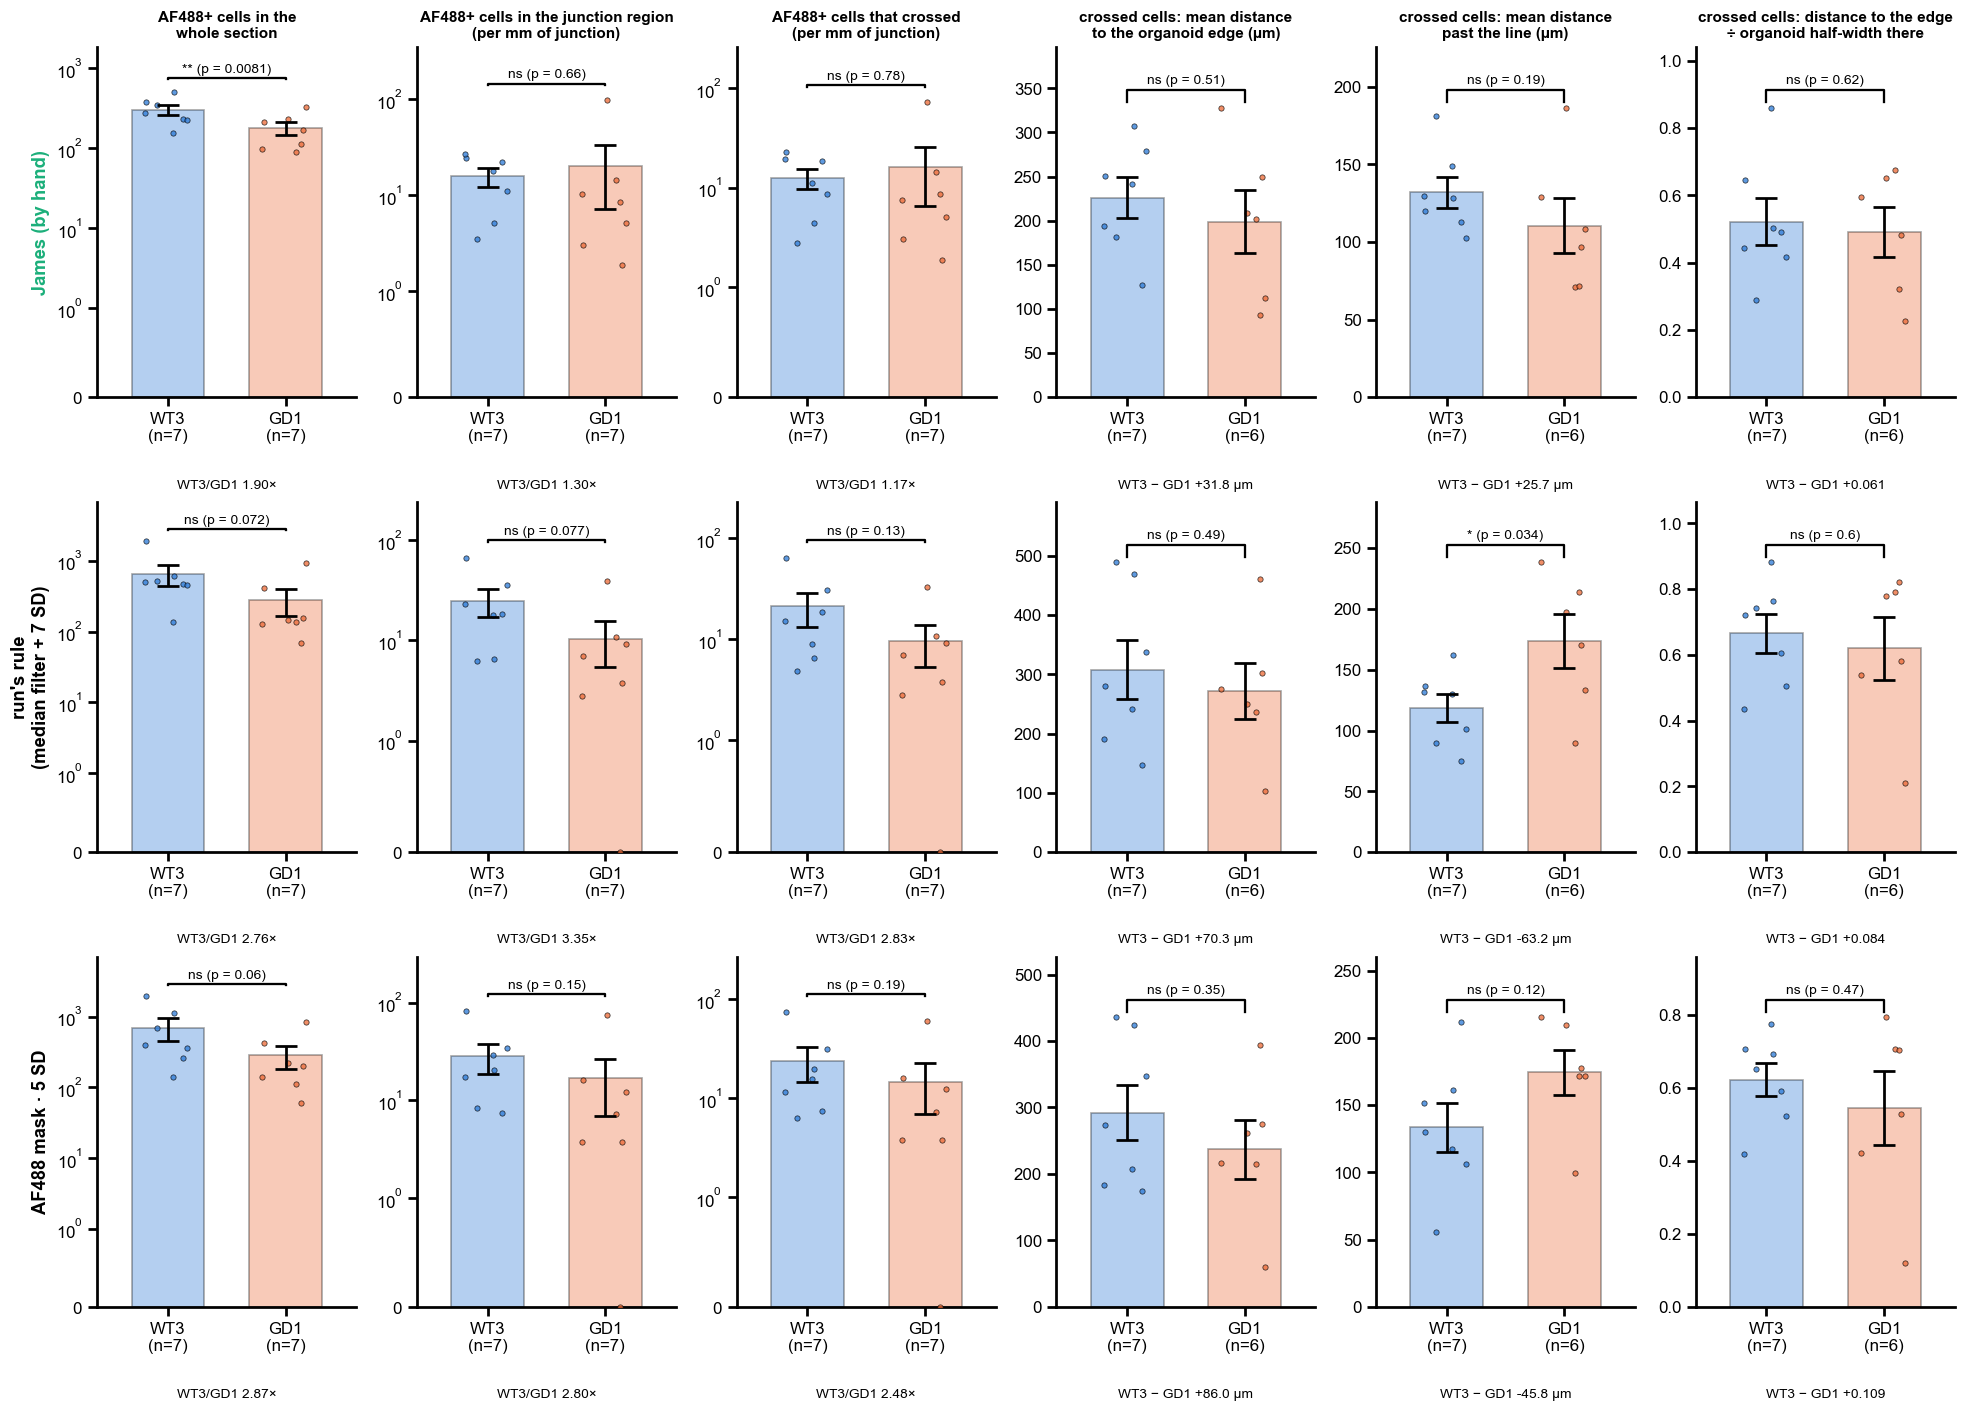

In [9]:
def dots_and_bar(ax, frame, column, p=None, log=False, seed=0):
    """Bar = mean ± SEM per genotype (black edge), every section as a black-edged dot, bracket with the p (04's)."""
    rng = np.random.default_rng(seed)
    top = 0.0
    for k, g in enumerate(GENOTYPES):
        y = pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").dropna().to_numpy()
        if not len(y):
            continue
        top = max(top, y.max())
        ax.bar(k, y.mean(), width=0.62, color=GENOTYPE_COLOURS[g], alpha=0.35, zorder=1, **EDGE)
        ax.errorbar(k, y.mean(), yerr=y.std(ddof=1) / np.sqrt(len(y)), color="black", capsize=7, capthick=1.8,
                    lw=1.8, zorder=4)
        ax.scatter(k + rng.uniform(-0.2, 0.2, len(y)), y, s=12, color=GENOTYPE_COLOURS[g], alpha=0.75, zorder=3,
                   edgecolor="black", linewidth=0.5)
    counts = [int(pd.to_numeric(frame.loc[frame["Genotype"] == g, column], errors="coerce").notna().sum())
              for g in GENOTYPES]
    ax.set_xticks(range(len(GENOTYPES)), [f"{g}\n(n={n})" for g, n in zip(GENOTYPES, counts)])
    ax.set_xlim(-0.6, len(GENOTYPES) - 0.4)
    if log:
        ax.set_yscale("symlog", linthresh=1)
    ax.set_ylim(bottom=0)
    if p is not None:
        y0 = top * (1.5 if log else 1.06)
        ax.plot([0, 0, 1, 1], [y0 * 0.96, y0, y0, y0 * 0.96], color="black", lw=1.5)
        ax.text(0.5, y0 * (1.06 if log else 1.01), f"{stars(p)} (p = {p:.2g})", ha="center", va="bottom", fontsize=9)
        ax.set_ylim(top=y0 * (2.4 if log else 1.14))


def effect_label(e):
    if e["kind"] == "fold":
        return f"WT3/GD1 {e['effect']:.2f}×"
    return f"WT3 − GD1 {e['effect']:+.1f} µm" if "µm" in e["outcome"] else f"WT3 − GD1 {e['effect']:+.3f}"


KEY = ["cells in whole section", "in junction per mm", "crossed per mm",
       "crossed: mean distance to edge (µm)", "crossed: mean distance past line (µm)", "crossed: edge ÷ local half-width"]
TITLES = {HAND: "James (by hand)", RUN_RULE: "run's rule\n(median filter + 7 SD)", "AF488 mask · 5 SD": "AF488 mask · 5 SD"}

fig, axes = plt.subplots(len(SHOWN), len(KEY), figsize=(3.0 * len(KEY), 4.3 * len(SHOWN)), squeeze=False)
for i, method in enumerate(SHOWN):
    for j, outcome in enumerate(KEY):
        ax = axes[i, j]
        e = effects14[(effects14["method"] == method) & (effects14["outcome"] == outcome)].iloc[0]
        dots_and_bar(ax, obs14[obs14["method"] == method], outcome, p=e["p"], log=OUTCOMES14[outcome][0] == "fold")
        ax.text(0.5, -0.26, effect_label(e), transform=ax.transAxes, ha="center", fontsize=9)
        if i == 0:
            ax.set_title(OUTCOMES14[outcome][1], fontsize=10)
        if j == 0:
            ax.set_ylabel(TITLES[method], color=HAND_COLOUR if method == HAND else "black", fontsize=12)
fig.tight_layout()
save(fig, "genotype_hand_vs_rules")
plt.show()

**The effect of every method on every outcome (forest plot).** One panel per outcome, one row per method, **James on top in green**. Dot = the mixed model's fold (log axis, 1× = no difference) or difference (0 = none), line = its 95 % CI. Filled = p < 0.05, hollow = not.

**How to read it.** If James's dot sits on the same side of the dashed line as the rules' dots, he leads to the same conclusion. If his CI overlaps theirs, his size of effect is compatible with theirs. Wide lines everywhere are what 14 sections give.

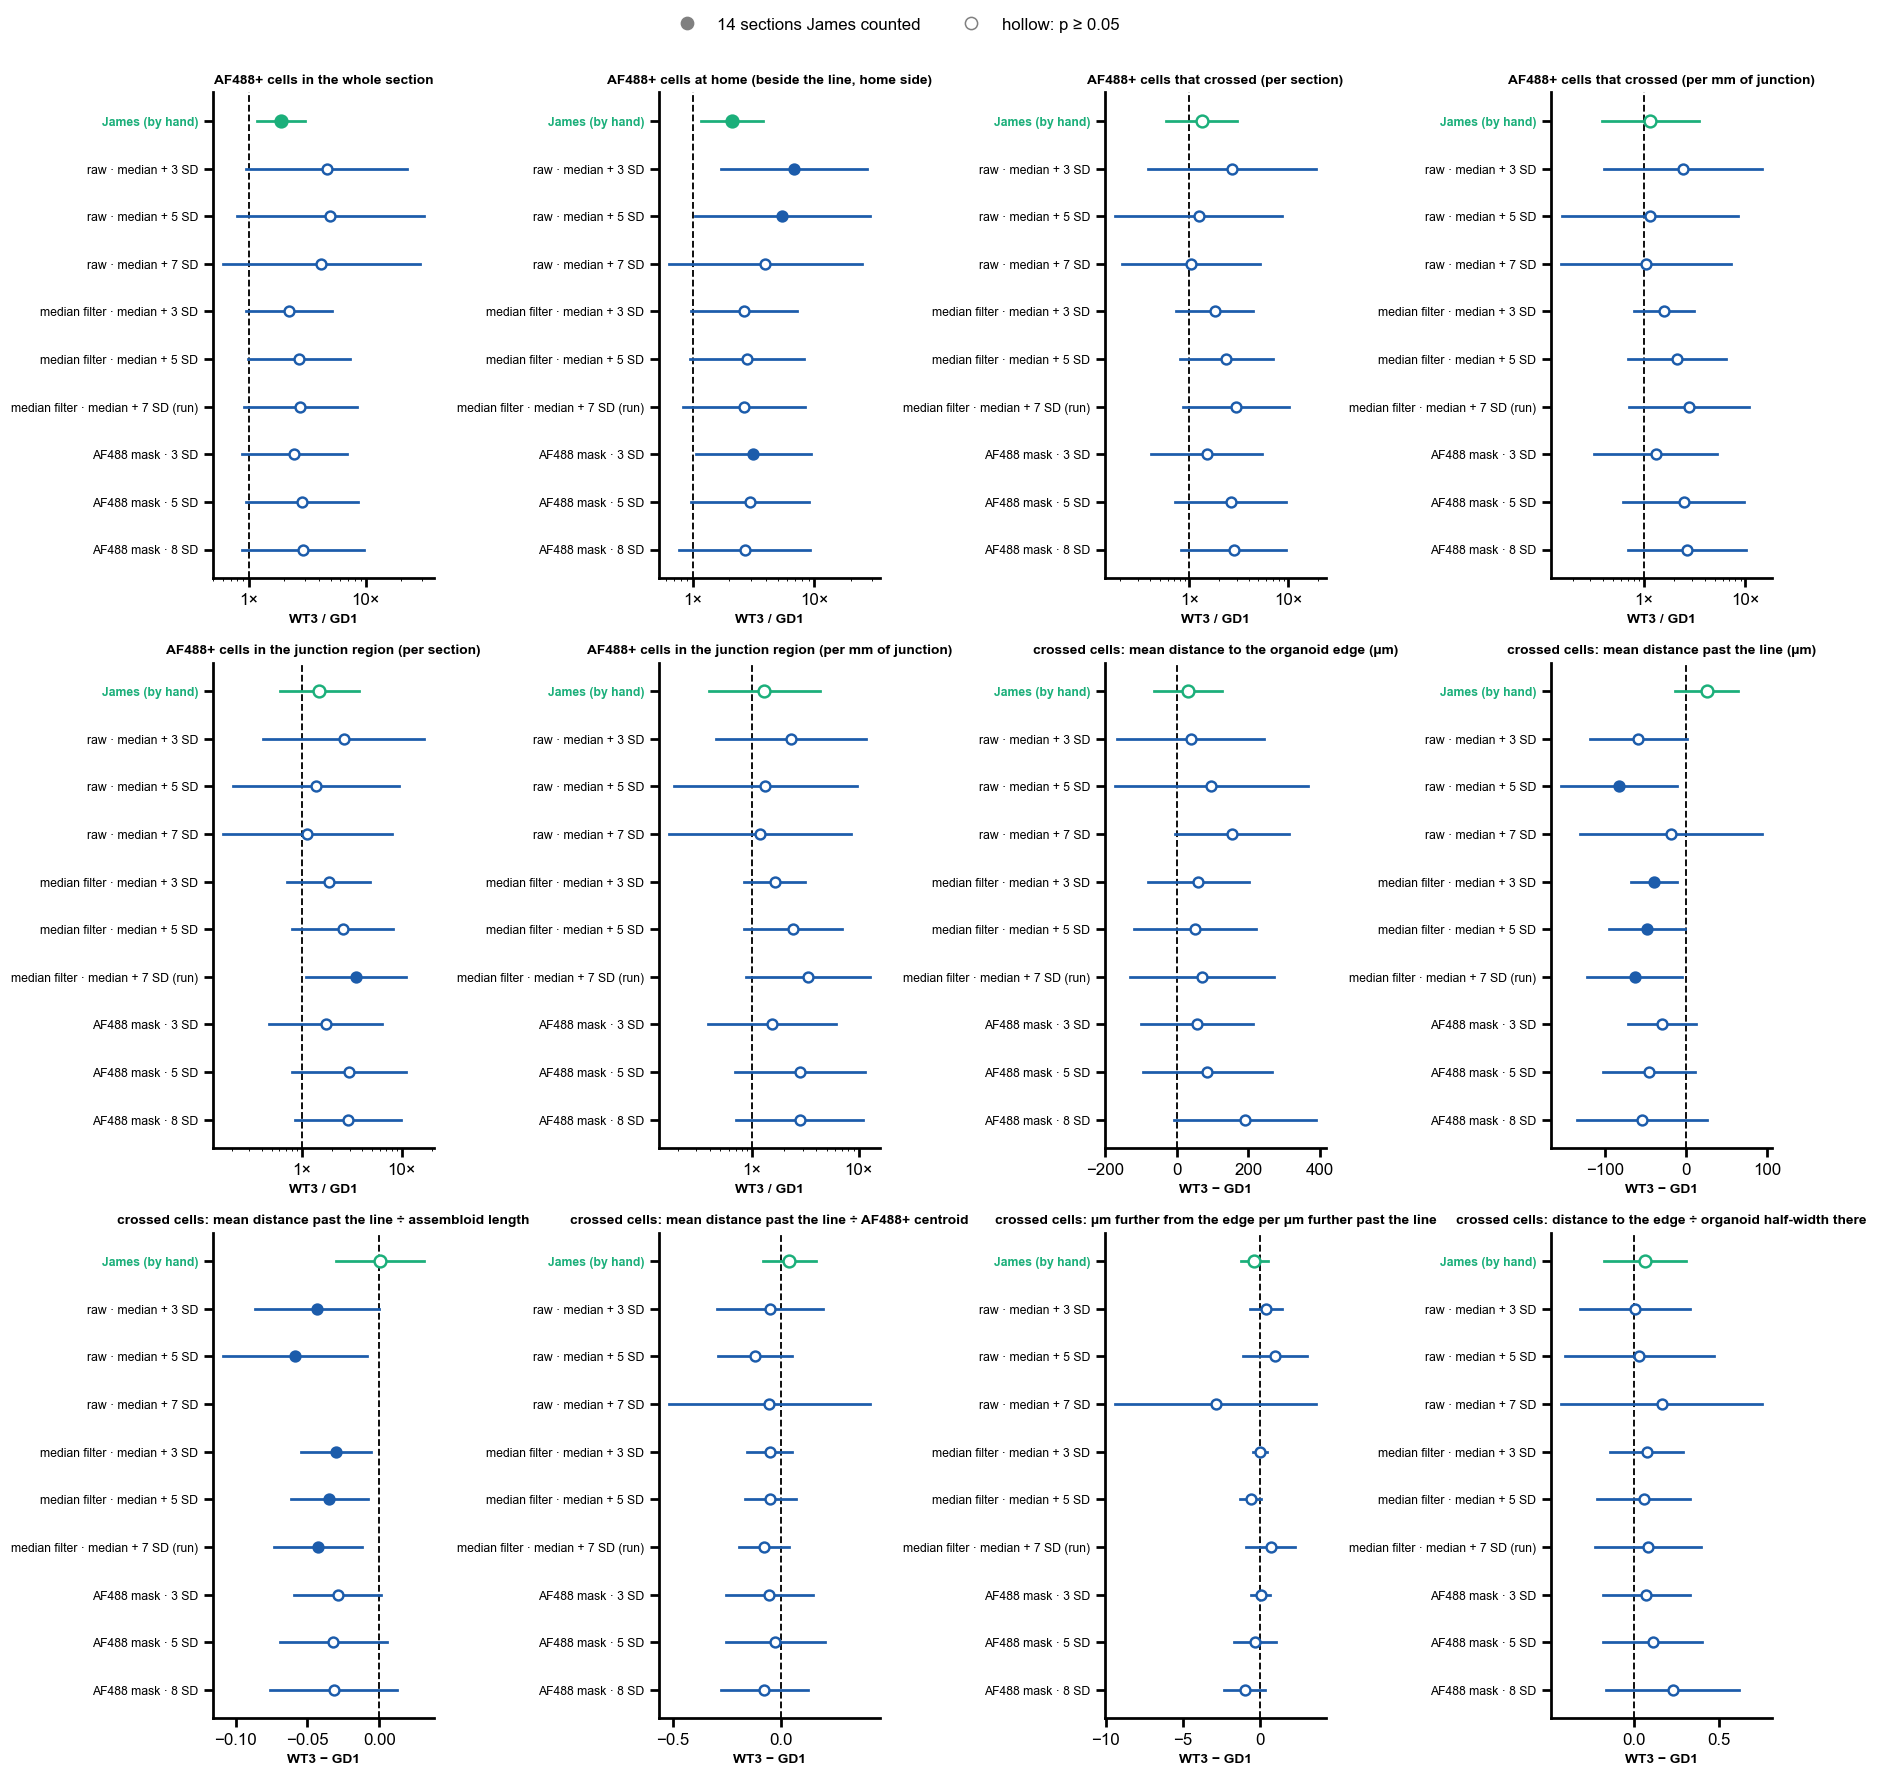

In [10]:
RULE_COLOUR = "#1c5cab"           # the rules' marks in the forest plots; James's are HAND_COLOUR


def forest(layers, outcomes, name, columns=4):
    """One panel per outcome: each method's effect (fold on a log axis, or difference) with its 95 % CI.
    *layers*: {label: (effects table, marker, vertical offset)}. Filled = p < 0.05, hollow = not."""
    rows = int(np.ceil(len(outcomes) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.1 * columns, 0.42 * len(METHODS) * rows + 1.2 * rows),
                             squeeze=False)
    for ax, outcome in zip(axes.flat, outcomes):
        kind = OUTCOMES14[outcome][0]
        for label, (table, marker, offset) in layers.items():
            part = table[table["outcome"] == outcome].set_index("method")
            for k, method in enumerate(METHODS):
                if method not in part.index or not np.isfinite(part.at[method, "effect"]):
                    continue
                e = part.loc[method]
                colour = HAND_COLOUR if method == HAND else RULE_COLOUR
                y = k + offset
                ax.plot([e["CI low"], e["CI high"]], [y, y], color=colour, lw=1.8, zorder=2)
                ax.scatter(e["effect"], y, marker=marker, s=60 if method == HAND else 42, zorder=3,
                           color=colour if e["p"] < 0.05 else "white", edgecolor=colour, linewidth=1.6)
        ax.axvline(1 if kind == "fold" else 0, color="black", lw=1.2, ls="--", zorder=1)
        if kind == "fold":
            ax.set_xscale("log")
            ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _p: f"{v:g}×"))
        ax.set_yticks(range(len(METHODS)), METHODS, fontsize=8)
        ax.get_yticklabels()[0].set_color(HAND_COLOUR)
        ax.get_yticklabels()[0].set_fontweight("bold")
        ax.set_ylim(len(METHODS) - 0.4, -0.6)
        ax.set_title(OUTCOMES14[outcome][1].replace("\n", " "), fontsize=9)
        ax.set_xlabel("WT3 / GD1" if kind == "fold" else "WT3 − GD1", fontsize=9)
    for ax in list(axes.flat)[len(outcomes):]:
        ax.axis("off")
    handles = [mpl.lines.Line2D([], [], marker=marker, ls="", mfc="grey", mec="grey", ms=8, label=label)
               for label, (_t, marker, _o) in layers.items()]
    handles += [mpl.lines.Line2D([], [], marker="o", ls="", mfc="white", mec="grey", ms=8, label="hollow: p ≥ 0.05")]
    fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    save(fig, name)
    plt.show()


forest({"14 sections James counted": (effects14, "o", 0.0)}, list(OUTCOMES14), "forest_14_sections")

## 6. Against the whole run

The same effects on the **whole run (614 sections, 36 slides)** for the nine rules, recomputed here as 04 does: the cells near the line from the 03/04 cache (`CACHE/<name>.parquet`), the masks' cover from `af488_mask/<name>/cells.parquet`, the same outcomes and mixed model. The cache holds only cells within 650 µm of the line, so the whole-section and at-home counts cannot be made for the run. Two checks are printed: the 14 sections give the same outcomes from the cache as from all their cells, and the run's effects match 04's (e.g. raw + 3 SD, crossed cells: 1.61×, p 0.095).

**How to read it.**

- **First table:** effect and stars (mixed model) for James on his 14 sections, for the run's rule and the mask (5 SD) on the same 14, and for both on all 614. The last column is James's Mann-Whitney p on sections / slide means.
- **Second table:** of the nine rules, how many go the **same way as James**, and how many reach p < 0.05, on the 14 sections and on the run.
- **Forest plot:** as above. Circles are the 14 sections, diamonds the whole run.
- Where James and the rules agree on the 14 but the run says the opposite, the 14 sections are not typical of the run. That is a sampling question, not a counting one.
- Where James disagrees with the rules on the same 14 sections, the counting matters.

In [11]:
import time

MASKS = OUT / "af488_mask"           # written by af488_masks.py
NOT_IN_CACHE = ["cells in whole section", "cells at home"]   # the cache stops 650 µm from the line


def run_sections():
    """Every section of the run, with genotype, experiment, slide, junction length and size (as 04)."""
    rows = []
    for path in sorted((RUN / "cells").glob("*.json")):
        info = json.loads(path.read_text(encoding="utf-8"))
        rows.append({"name": info["sample"], "length (mm)": info.get("junction_length_um", np.nan) / 1000})
    run = pd.DataFrame(rows).merge(design[["name", "Genotype", "Experiment", "slide"]], on="name").set_index("name")
    for column in SCALES.values():
        run[column] = scales[column]
    return run


def run_cells(name):
    """One section's cells near the line from the 03/04 cache, with `away` (04's sign) and the masks' cover."""
    c = pd.read_parquet(CACHE / f"{name}.parquet")
    pos = c[f"{CHANNEL} positive"].to_numpy(bool) & c["beside"].to_numpy(bool)
    sign = -1.0 if pos.sum() >= 5 and np.median(c.loc[pos, "d"]) > 0 else 1.0
    c["away"] = c["d"] * sign
    target = MASKS / name / "cells.parquet"
    if target.exists():
        cover = pd.read_parquet(target).set_index("Label")
        for column in cover.columns:
            c[column] = c["label"].map(cover[column]).to_numpy()
    else:
        for mask in ("kmad3", "kmad5", "kmad8"):
            c[f"cover {mask}"] = np.nan
    return c


start = time.time()
run = run_sections()
records = []
for name, s in run.iterrows():
    c = run_cells(name)
    widths = half_widths(c["away"].to_numpy(float), c["beside"].to_numpy(bool), c["edge"].to_numpy(float))
    who = {"name": name, "Genotype": s["Genotype"], "Experiment": s["Experiment"], "slide": s["slide"]}
    for rule in RULE_NAMES:
        row = section_outcomes(s, c.loc[positive(c, rule), PLACE], widths)
        records.append({**who, "method": rule, **row, **{o: np.nan for o in NOT_IN_CACHE}})
obs614 = pd.DataFrame(records)
print(f"the whole run: {len(run)} sections on {run['slide'].nunique()} slides, read in {time.time() - start:.0f} s")

# Check: the 14 sections from the cache give the same rule outcomes as from all their cells.
mine = obs14[obs14["method"] != HAND].set_index(["name", "method"])
theirs = obs614.set_index(["name", "method"]).loc[mine.index]
same = [o for o in OUTCOMES14 if o not in NOT_IN_CACHE]
gap = (mine[same] - theirs[same]).abs().max().max()
print(f"the 14 sections, cache against all cells: largest difference in any outcome {gap:.3g} (0 expected)")

OUTCOMES614 = {o: v for o, v in OUTCOMES14.items() if o not in NOT_IN_CACHE}
effects614 = effects_of(obs614, RULE_NAMES, OUTCOMES614)
print("which model fitted (614 sections):", effects614["model"].value_counts().to_dict())

the whole run: 614 sections on 36 slides, read in 9 s
the 14 sections, cache against all cells: largest difference in any outcome 5.27e-06 (0 expected)


which model fitted (614 sections): {'slide random + experiment': 90}


,James · 14,run's rule · 14,mask 5 SD · 14,run's rule · 614,mask 5 SD · 614,James MW p (sections / slides)
cells in whole section,1.90× **,2.76× ns,2.87× ns,–,–,0.038 / 0.082
cells at home,2.10× *,2.62× ns,2.94× ns,–,–,0.047 / 0.082
crossed cells,1.33× ns,2.98× ns,2.61× ns,2.37× ***,1.96× *,0.3 / 0.65
crossed per mm,1.17× ns,2.83× ns,2.48× ns,2.70× ***,2.27× **,0.46 / 0.66
cells in junction,1.49× ns,3.47× *,2.96× ns,2.76× ***,2.27× **,0.18 / 0.41
in junction per mm,1.30× ns,3.35× ns,2.80× ns,3.14× ***,2.61× **,0.32 / 0.66
crossed: mean distance to edge (µm),+31.8 ns,+70.3 ns,+86.0 ns,-70.5 ***,-75.1 ***,0.63 / 0.54
crossed: mean distance past line (µm),+25.7 ns,-63.2 *,-45.8 ns,-17.4 **,-20.2 ***,0.23 / 0.33
crossed: distance past line ÷ assembloid length,+0.001 ns,-0.043 **,-0.032 ns,-0.013 ***,-0.016 ***,0.29 / 0.66
crossed: distance past line ÷ AF488+ centroid,+0.038 ns,-0.078 ns,-0.026 ns,+0.059 *,+0.063 *,0.18 / 0.33


,James,rules same way · 14,rules p < 0.05 · 14,rules same way · 614,rules p < 0.05 · 614
outcome,,,,,
cells in whole section,1.90× **,9/9,0/9,–,–
cells at home,2.10× *,9/9,3/9,–,–
crossed cells,1.33× ns,9/9,0/9,9/9,6/9
crossed per mm,1.17× ns,9/9,0/9,9/9,8/9
cells in junction,1.49× ns,9/9,1/9,9/9,8/9
in junction per mm,1.30× ns,9/9,0/9,9/9,8/9
crossed: mean distance to edge (µm),+31.8 ns,9/9,0/9,0/9,9/9
crossed: mean distance past line (µm),+25.7 ns,0/9,4/9,0/9,5/9
crossed: distance past line ÷ assembloid length,+0.001 ns,0/8,5/8,0/9,8/9


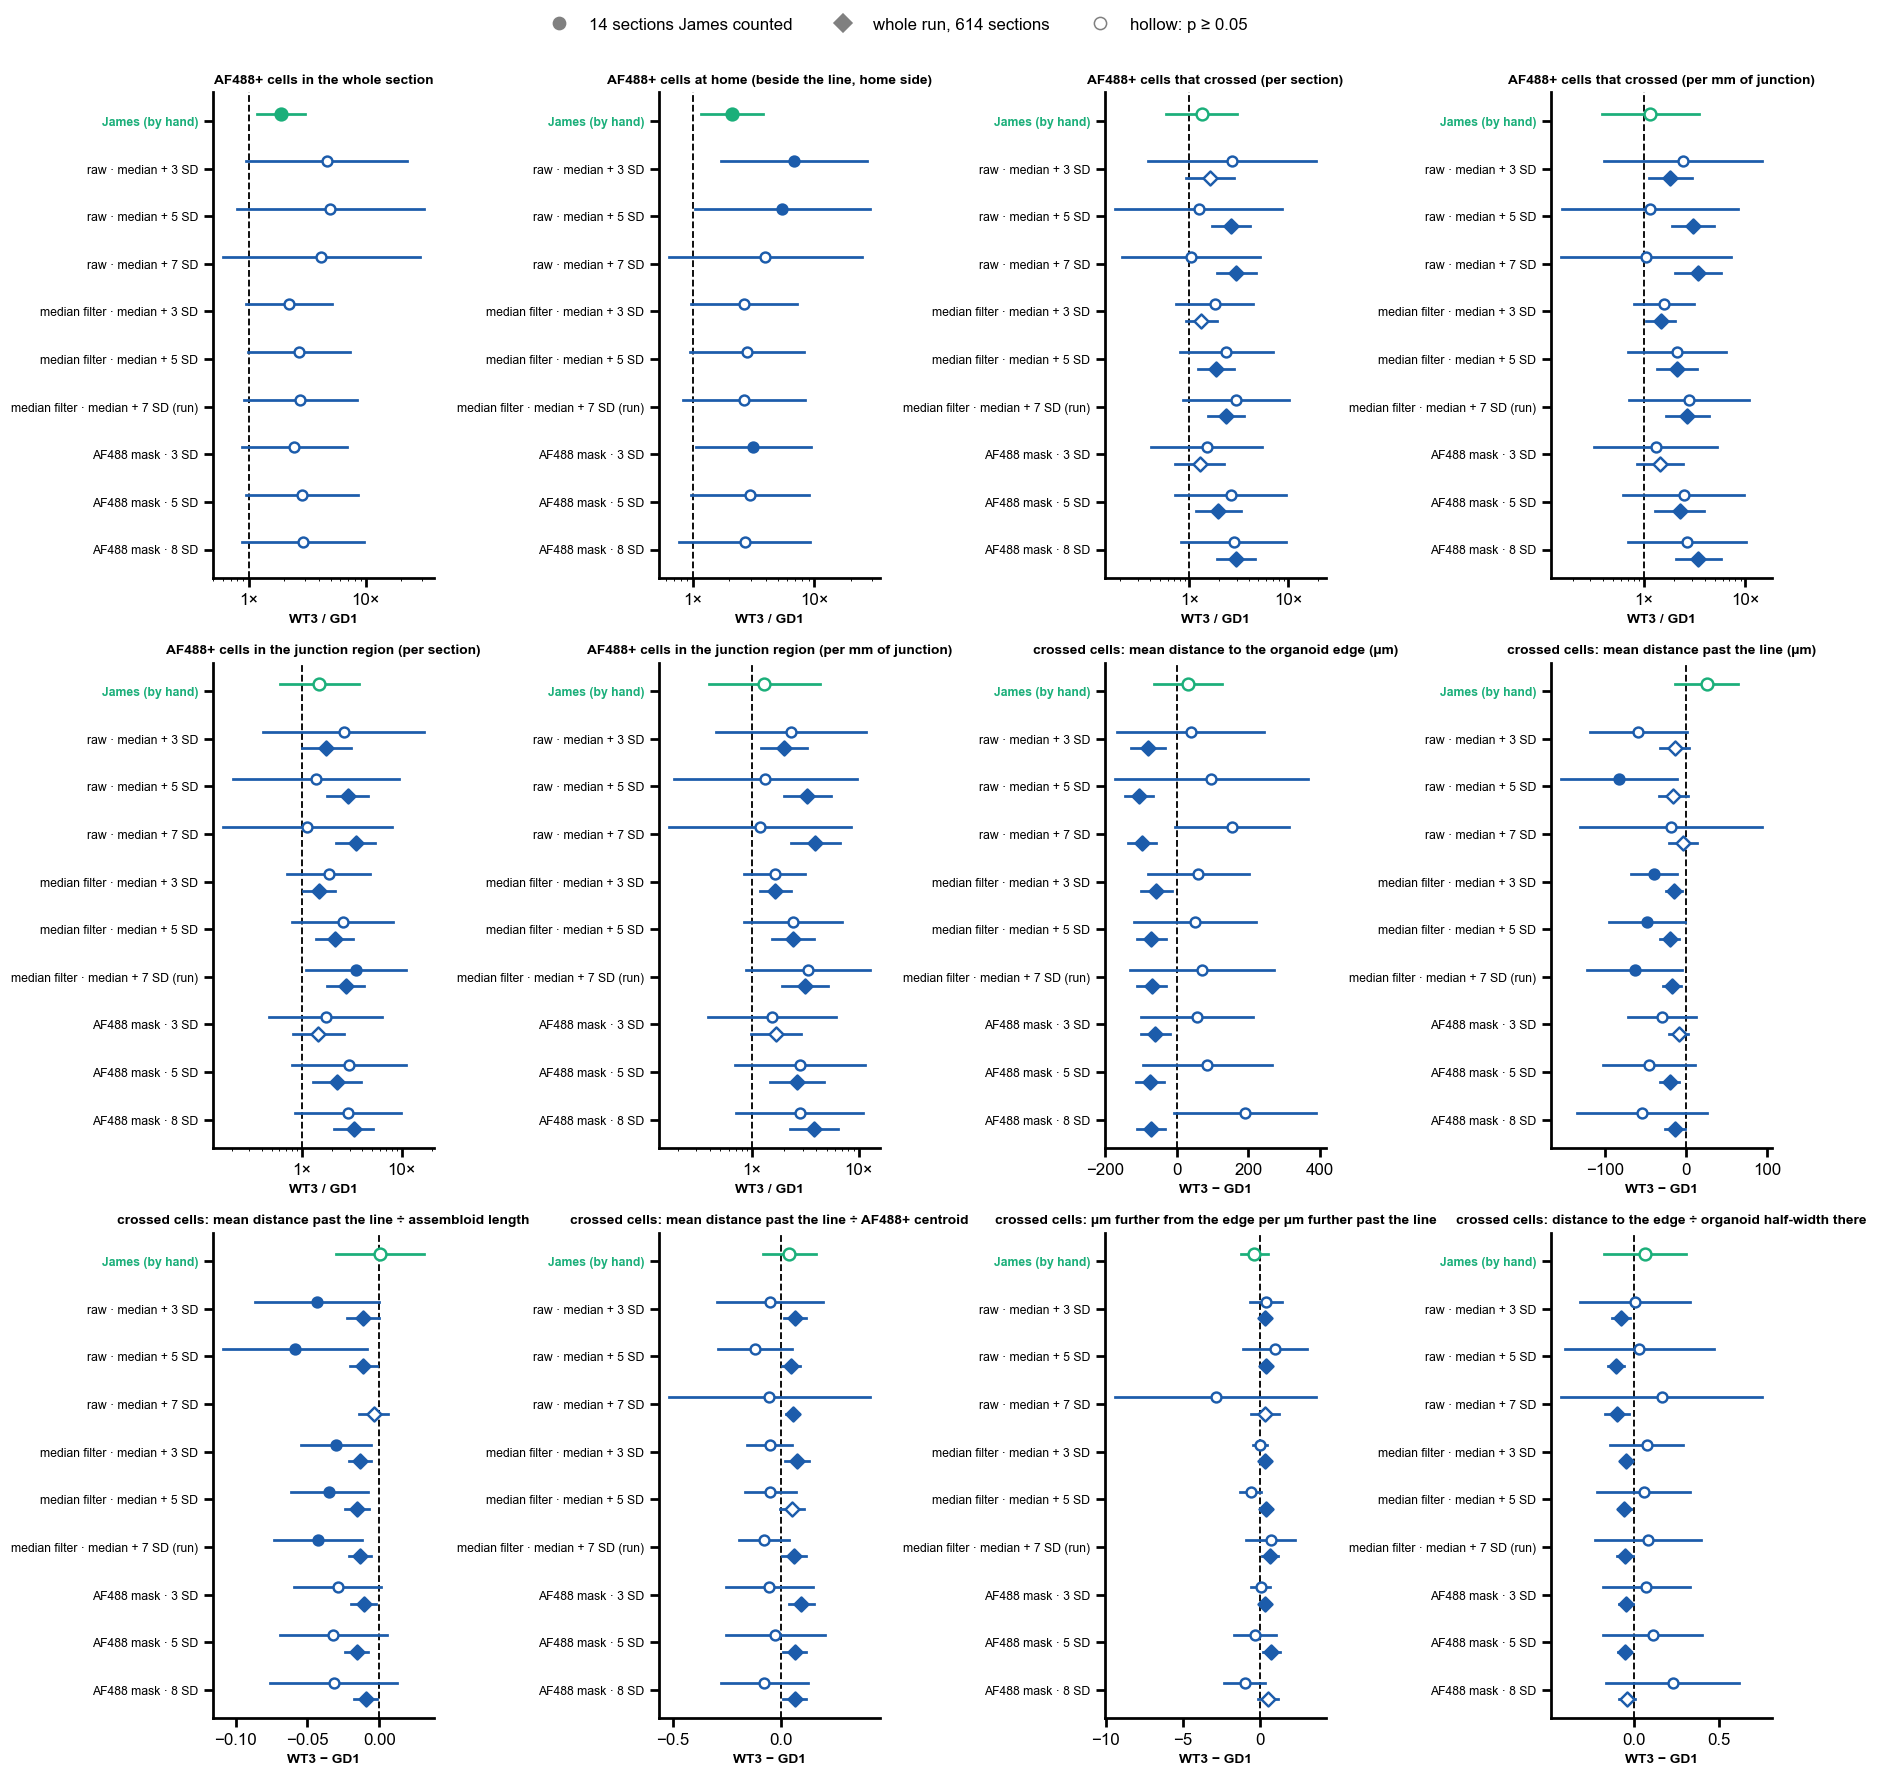

In [12]:
def direction(e):
    """+1 when the figure is higher in WT3, −1 when higher in GD1."""
    return np.sign(np.log(e["effect"]) if e["kind"] == "fold" else e["effect"])


def fmt(e, outcome):
    if not np.isfinite(e["effect"]):
        return "–"
    size = f"{e['effect']:.2f}×" if e["kind"] == "fold" else f"{e['effect']:+.1f}" if "µm" in outcome else f"{e['effect']:+.3f}"
    return f"{size} {stars(e['p'])}"


both = pd.concat([effects14.assign(set="14"), effects614.assign(set="614")], ignore_index=True)
both["direction"] = both.apply(direction, axis=1)
key = both.set_index(["outcome", "method", "set"])

# The headline table: effect and stars (mixed model), James beside the run's rule and the mask on 14 and 614 sections.
COLUMNS = {"James · 14": (HAND, "14"), "run's rule · 14": (RUN_RULE, "14"), "mask 5 SD · 14": ("AF488 mask · 5 SD", "14"),
           "run's rule · 614": (RUN_RULE, "614"), "mask 5 SD · 614": ("AF488 mask · 5 SD", "614")}
headline = pd.DataFrame({label: [fmt(key.loc[(o, m, n)], o) if (o, m, n) in key.index else "–" for o in OUTCOMES14]
                         for label, (m, n) in COLUMNS.items()}, index=list(OUTCOMES14))
headline["James MW p (sections / slides)"] = [
    f"{key.loc[(o, HAND, '14'), 'MW p (sections)']:.2g} / {key.loc[(o, HAND, '14'), 'MW p (slide means)']:.2g}"
    for o in OUTCOMES14]
display(headline)

# Direction agreement with James: of the 9 rules, how many go the same way on the 14 sections, and on the run.
same_way = []
for o in OUTCOMES14:
    hand = key.loc[(o, HAND, "14")]
    row = {"outcome": o, "James": fmt(hand, o)}
    for n in ("14", "614"):
        rules = both[(both["outcome"] == o) & (both["set"] == n) & (both["method"] != HAND)].dropna(subset=["effect"])
        row[f"rules same way · {n}"] = f"{int((rules['direction'] == hand['direction']).sum())}/{len(rules)}" if len(rules) else "–"
        row[f"rules p < 0.05 · {n}"] = f"{int((rules['p'] < 0.05).sum())}/{len(rules)}" if len(rules) else "–"
    same_way.append(row)
display(pd.DataFrame(same_way).set_index("outcome"))

forest({"14 sections James counted": (effects14, "o", -0.15), "whole run, 614 sections": (effects614, "D", 0.2)},
       list(OUTCOMES14), "forest_14_vs_run")

**Section by section, James against the run's rule (interactive).** One panel per outcome, one dot per section. Hover for the section's name, slide and junction length. Change `AGAINST` to compare with another rule. The table gives the rank correlation (Spearman ρ) and how many the rule counts per dot James put, median over sections. Saved as `james_vs_rule.html` in `FIGURES`.

In [13]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook"          # plotly figures embedded in the notebook (work offline)
SCATTER = ["cells in whole section", "in junction per mm", "crossed per mm", "crossed: mean distance to edge (µm)"]
AGAINST = RUN_RULE                          # change to any rule in RULE_NAMES

pairs = (obs14[obs14["method"].isin([HAND, AGAINST])]
         .melt(id_vars=["name", "method"], value_vars=SCATTER, var_name="outcome")
         .pivot(index=["name", "outcome"], columns="method", values="value")
         .rename(columns={HAND: "James", AGAINST: "rule"}).reset_index()
         .join(sections[["Genotype", "slide", "length (mm)"]], on="name"))
pairs["section"] = pairs["name"].map(short)
scatter = px.scatter(pairs, x="James", y="rule", color="Genotype", facet_col="outcome", facet_col_wrap=4,
                     color_discrete_map=GENOTYPE_COLOURS, category_orders={"Genotype": GENOTYPES, "outcome": SCATTER},
                     hover_name="section", hover_data={"slide": True, "length (mm)": ":.2f", "James": ":.1f", "rule": ":.1f",
                                                       "outcome": False},
                     labels={"James": "James (by hand)", "rule": AGAINST}, height=430, width=1500)
scatter.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
scatter.update_xaxes(matches=None, showticklabels=True, rangemode="tozero")
scatter.update_yaxes(matches=None, showticklabels=True, rangemode="tozero")
scatter.update_traces(marker=dict(size=11, line=dict(width=1.2, color="black")))
scatter.update_layout(template="simple_white", title=f"James against {AGAINST}, per section (hover for the name)")
scatter.write_html(FIGURES / "james_vs_rule.html", include_plotlyjs="cdn")
scatter.show()
display(pairs.groupby("outcome").apply(lambda t: pd.Series({
    "Spearman ρ": stats.spearmanr(t["James"], t["rule"], nan_policy="omit").correlation,
    "median rule ÷ James": float(np.nanmedian(t["rule"] / t["James"].replace(0, np.nan)))})).loc[SCATTER].round(2))

,Spearman ρ,median rule ÷ James
outcome,,
cells in whole section,0.93,1.49
in junction per mm,0.77,1.14
crossed per mm,0.77,1.25
crossed: mean distance to edge (µm),0.66,1.19


## 7. Where James and the rules disagree: example cells

Four kinds of cell, set by James's dot and the run's rule (median filter + 7 SD):

| kind | James | run's rule | drawn from |
|---|---|---|---|
| **both** | dot | AF488+ | anywhere in the section |
| **missed by the rule** | dot | not AF488+ | near the junction: in the junction region, or crossed (past the line, up to 300 µm) |
| **rule only** | no dot | AF488+ | near the junction |
| **dot without a cell** | dot, no segmented cell within 7 µm | — | anywhere in the section |

Missed and rule-only cells are drawn near the junction because those are the ones that move the crossed-cell counts; a kind falls back to the whole section when a section has none there. For each kind, `N_PER_KIND` cells drawn at random (`SEED`), half WT3 and half GD1, each from a different section.

**How to read it.** Each cell twice, over `CROP_UM`: top, AF488 as measured (maximum over z); below, AF488 less its local median (45 µm) — what the run's rule averages. Same brightness range in every picture (`DISPLAY`, `DISPLAY_FILTERED`), so a dim cell looks dim. The cell's nucleus is outlined in **white**, its grown region (nucleus + 6 µm, what the means are taken over) **dashed**, other nuclei faint grey; James's dots are **green rings** (every dot in view, not only this cell's). The title gives where the cell is (region / crossed = past the line / home), and its filtered mean against the run's bar (`M7 x / bar y`). Under each, one box per rule — **filled = called AF488+** — raw R3 R5 R7 (purple), median filter M3 M5 M7 (blue; M7 is the run's), AF488 masks K3 K5 K8 (green), and **J** = James's dot. A dot without a cell has no rule calls: its title gives the distance to the nearest segmented cell.

In [14]:
import logging
import sys

logging.getLogger("tifffile").setLevel(logging.ERROR)   # OME headers with odd characters: harmless

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import tifffile  # noqa: E402
from scipy.spatial import cKDTree  # noqa: E402
from skimage.segmentation import find_boundaries  # noqa: E402

from microscopy_viewer import junction_analysis as ja  # noqa: E402
from microscopy_viewer import loaders  # noqa: E402

# ---------------------------------------------------------------- Settings for the pictures
SEED = 0
N_PER_KIND = 6                    # cells per kind (half WT3, half GD1), each from a different section
N_SUMMARY = 4                     # cells per kind in the one-figure summary
CROP_UM = 40.0                    # side of a cell's picture
PREFER_NEAR = True                # missed / rule-only cells drawn in the region or crossed zone when the section has some
DISPLAY = (150.0, 1200.0)         # raw AF488 shown from black to full green
DISPLAY_FILTERED = (0.0, 900.0)   # AF488 less its local median, the same
# ----------------------------------------------------------------------------------------

SHORT = dict(zip(RULE_NAMES, ["R3", "R5", "R7", "M3", "M5", "M7", "K3", "K5", "K8"]))
RULE_COLOURS = {"R": "#6250d6", "M": "#1c5cab", "K": "#1baf7a", "J": HAND_COLOUR}
GREEN = mpl.colors.LinearSegmentedColormap.from_list("green", ["black", "#00ff3c"])
MARGIN_UM = 1.5 * ja.MEDIAN_UM    # read round the crop so its local median is that of its surroundings
RUN_SHORT = SHORT[RUN_RULE]

# Every cell of the 14 sections with each rule's call, James's dot and where it lies.
table = []
for name, s in sections.iterrows():
    c = cells[name]
    frame = pd.DataFrame(np.column_stack([positive(c, rule) for rule in RULE_NAMES]), columns=list(SHORT.values()))
    frame["J"] = c["clicked"].to_numpy(bool)
    frame["name"], frame["Genotype"] = name, s["Genotype"]
    for column in ("label", "y", "x", "away", "region", "beside", RAW, FILTERED):
        frame[column] = c[column].to_numpy()
    centre, sd = robust(c.loc[c["region"], FILTERED])
    frame["run's bar"] = centre + RULES[RUN_RULE][1] * sd
    table.append(frame)
table = pd.concat(table, ignore_index=True)
table["crossed"] = table["beside"] & (table["away"] > GAP_UM) & (table["away"] <= NEAR_UM)
table["where"] = np.where(table["crossed"], "crossed", np.where(table["region"], "region", "home"))
table.loc[~table["region"] & (table["away"] > NEAR_UM), "where"] = "far past the line"
# The nearest of James's dots to each cell: a "rule only" cell may sit beside a dot matched to a neighbour.
for name, part in table.groupby("name"):
    dots = clicks.loc[clicks["name"] == name, ["y", "x"]].to_numpy()
    table.loc[part.index, "nearest dot (µm)"] = cKDTree(dots).query(part[["y", "x"]].to_numpy())[0]

# James's dots without a segmented cell, placed like the cells.
lonely = clicks[~clicks["matched"]].copy()
for name, part in lonely.groupby("name"):
    distance, _nearest = cKDTree(cells[name][["y", "x"]].to_numpy()).query(part[["y", "x"]].to_numpy())
    lonely.loc[part.index, "nearest cell (µm)"] = distance
lonely["where"] = np.where(lonely["crossed"], "crossed", np.where(lonely["region"], "region", "home"))

KINDS = {
    "both": table[table["J"] & table[RUN_SHORT]],
    "missed by the rule": table[table["J"] & ~table[RUN_SHORT]],
    "rule only": table[~table["J"] & table[RUN_SHORT]],
    "dot without a cell": lonely,
}
NEAR_KINDS = ("missed by the rule", "rule only")
NEAR_WHERE = ("region", "crossed")

print("cells of each kind (near the junction = in the junction region or crossed: past the line, up to 300 µm):")
summary_rows = {}
for kind, frame in KINDS.items():
    row = {"cells": len(frame), "near the junction": int(frame["where"].isin(NEAR_WHERE).sum())}
    if kind != "dot without a cell":
        row["median filtered mean ÷ run's bar"] = float(np.median(frame[FILTERED] / frame["run's bar"]))
        row["called by ≥ 1 rule"] = float(frame[list(SHORT.values())].any(axis=1).mean())
        row["a dot within 10 µm"] = float((frame["nearest dot (µm)"] <= 10).mean())
    else:
        row["median distance to a cell (µm)"] = float(frame["nearest cell (µm)"].median())
    summary_rows[kind] = row
display(pd.DataFrame(summary_rows).T.round(2))


def draw(frame, n, rng, near_first):
    """n rows of *frame*, half per genotype, each from a different section; near the junction when asked."""
    picked = []
    for g, k in zip(GENOTYPES, (n - n // 2, n // 2)):
        part = frame[frame["Genotype"] == g].sample(frac=1.0, random_state=int(rng.integers(1 << 31)))
        if near_first:   # near cells first, so each section gives a near one when it has any
            part = part.assign(_rank=part["where"].map({"crossed": 0, "region": 1}).fillna(2)).sort_values("_rank", kind="stable")
        picked.append(part.drop_duplicates("name").head(k))
    return pd.concat(picked)


rng = np.random.default_rng(SEED)
chosen = {kind: draw(frame, N_PER_KIND, rng, PREFER_NEAR and kind in NEAR_KINDS).reset_index(drop=True)
          for kind, frame in KINDS.items()}
print("the cells drawn:")
display(pd.concat({kind: f[["Genotype", "name", "where"]].assign(name=f["name"].map(short))
                   for kind, f in chosen.items()}))

cells of each kind (near the junction = in the junction region or crossed: past the line, up to 300 µm):


,cells,near the junction,median filtered mean ÷ run's bar,called by ≥ 1 rule,a dot within 10 µm,median distance to a cell (µm)
both,1881.0,70.0,2.27,1.00,1.0,NaN
missed by the rule,1107.0,85.0,0.63,0.82,1.0,NaN
rule only,4669.0,133.0,1.61,1.00,0.5,NaN
dot without a cell,389.0,15.0,NaN,NaN,NaN,12.06


the cells drawn:


Genotype         name    where
both               0      WT3   020-019_s9     home
                   1      WT3   028-027_s9     home
                   2      WT3  019-018_s16     home
                   3      GD1   039-038_s1     home
                   4      GD1   038-037_s9     home
                   5      GD1   051-050_s3     home
missed by the rule 0      WT3   032-031_s9  crossed
                   1      WT3   020-019_s9  crossed
                   2      WT3  032-031_s25  crossed
                   3      GD1  052-051_s15  crossed
                   4      GD1   038-037_s9  crossed
                   5      GD1  057-056_s22  crossed
rule only          0      WT3   037-036_s3  crossed
                   1      WT3   028-027_s9  crossed
                   2      WT3  034-033_s25  crossed
                   3      GD1  057-056_s10  crossed
                   4      GD1   038-037_s9  crossed
                   5      GD1  057-056_s22  crossed
dot without a cell 0      WT3   032-031_s9     home
                   1      WT3   037-036_s3     home
                   2      WT3  032-031_s25     home
                   3      GD1  057-056_s22     home
                   4      GD1  038-037_s11     home
                   5      GD1  057-056_s10     home

24 crops read from 14 sections


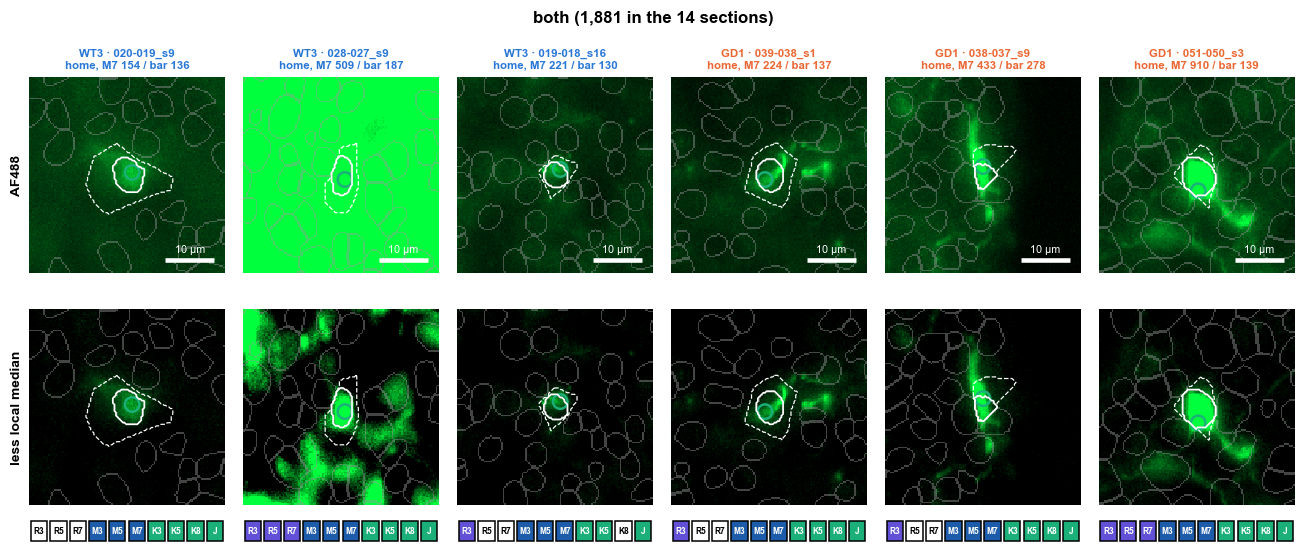

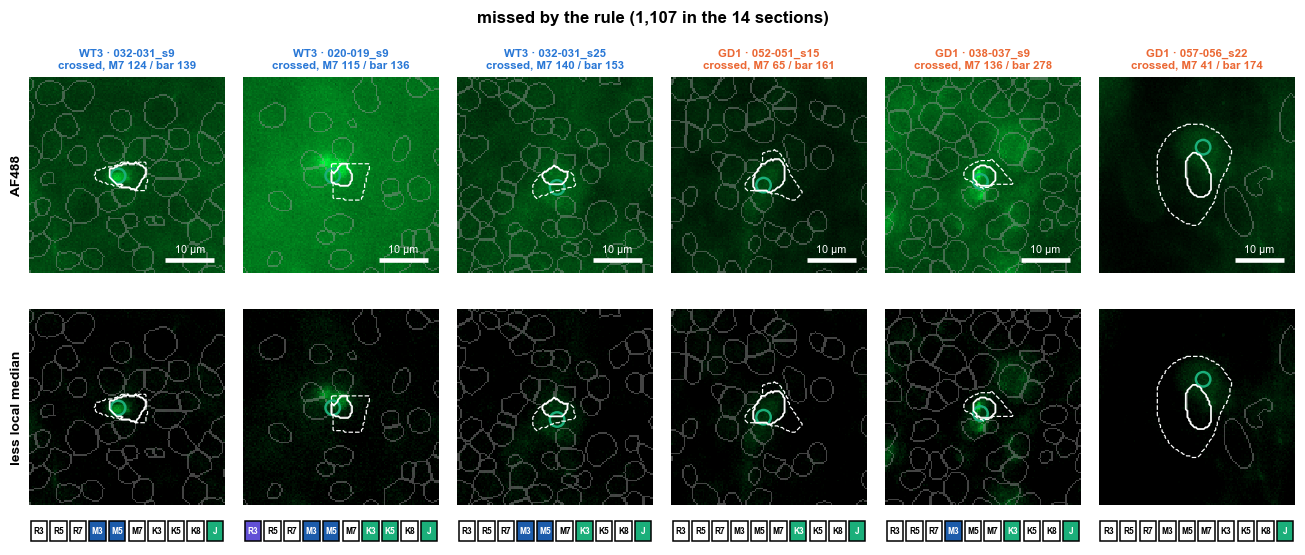

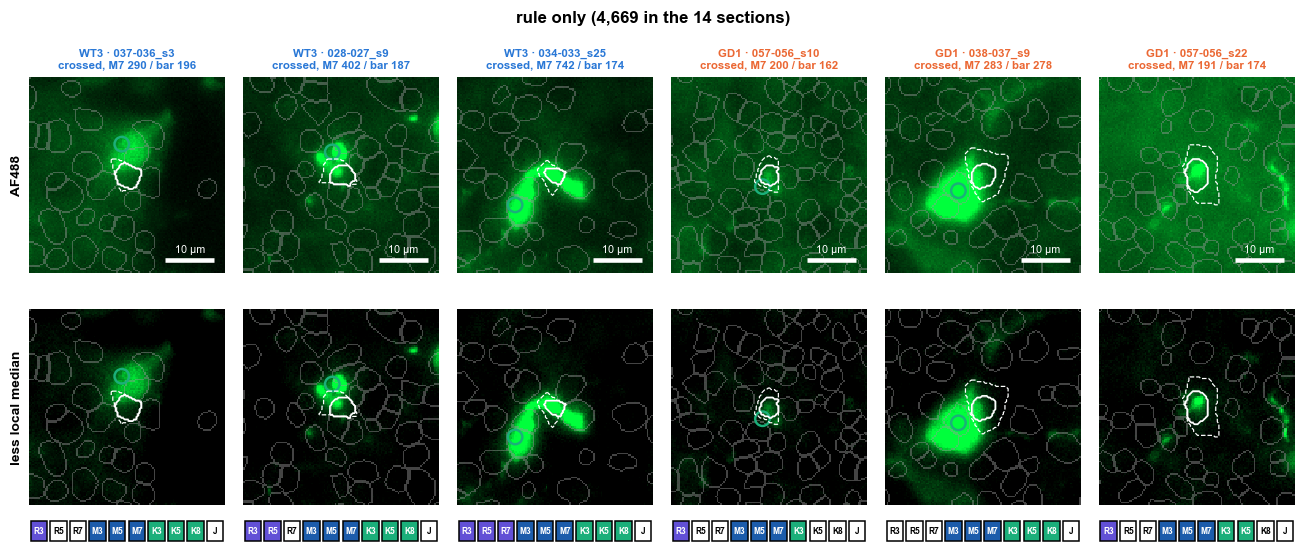

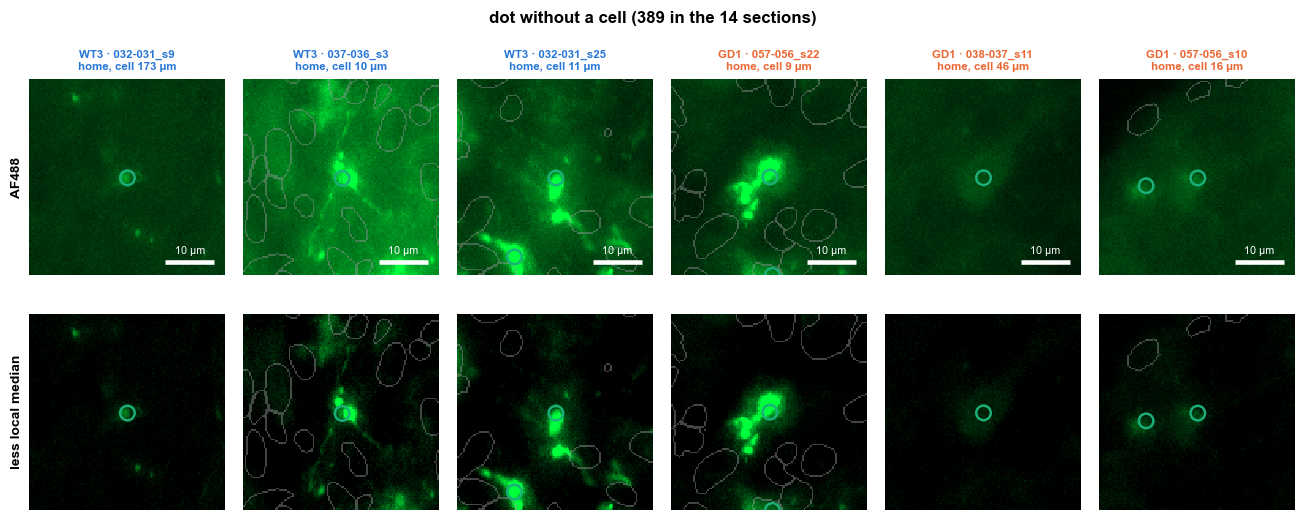

In [15]:
def section_info(name):
    return json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))


def read_crops(name, centres_um, side_um=CROP_UM, margin_um=MARGIN_UM):
    """Per centre: AF488 (maximum over z), AF488 less its local median, nuclei and grown labels over *side_um*.

    Only a window round each centre is read. The local median is worked out over the
    window plus *margin_um* on each side, so it is that of the cell's surroundings,
    as the run's (which is worked out over the whole section).
    """
    info = section_info(name)
    voxel = float(info["voxel_yx"][0])
    height, width = info["shape_yx"]
    nuclei = tifffile.imread(RUN / info["nuclei_file"])
    grown = tifffile.imread(RUN / info["grown_file"])
    path = Path(info["file"])
    specs = loaders.load_path(path)
    crops = []
    try:
        names_ = [str(spec.channel_name or spec.name) for spec in specs]
        spec = specs[names_.index(CHANNEL)]
        for cy_um, cx_um in centres_um:
            half, pad = int(round(side_um / 2 / voxel)), int(round(margin_um / voxel))
            cy, cx = int(round(cy_um / voxel)), int(round(cx_um / voxel))
            outer = (slice(max(cy - half - pad, 0), min(cy + half + pad, height)),
                     slice(max(cx - half - pad, 0), min(cx + half + pad, width)))
            inner = (slice(max(cy - half, 0), min(cy + half, height)), slice(max(cx - half, 0), min(cx + half, width)))
            cut = (slice(inner[0].start - outer[0].start, inner[0].stop - outer[0].start),
                   slice(inner[1].start - outer[1].start, inner[1].stop - outer[1].start))
            plane = ja._plane(spec, outer).astype(np.float32)
            crops.append({"raw": plane[cut], "filtered": ja.less_local_median(plane, voxel)[cut],
                          "nuclei": nuclei[inner], "grown": grown[inner], "voxel": voxel,
                          "origin_um": (inner[0].start * voxel, inner[1].start * voxel)})
    finally:
        loaders.release(path)
    return crops


def scale_bar(ax, image, voxel, um):
    h, w = image.shape
    length = um / voxel
    ax.plot([w - length - 0.06 * w, w - 0.06 * w], [h - 0.07 * h] * 2, color="white", lw=3, solid_capstyle="butt")
    ax.text(w - length / 2 - 0.06 * w, h - 0.1 * h, f"{um:g} µm", color="white", ha="center", va="bottom", fontsize=7)


def call_strip(ax, row, where=-0.2):
    """One box per rule and one for James under a picture: filled when it calls the cell AF488+."""
    strip = ax.inset_axes([0.0, where, 1.0, 0.13])
    boxes = list(SHORT.values()) + ["J"]
    for k, key in enumerate(boxes):
        on = bool(row[key]) if key in row else False
        strip.add_patch(mpl.patches.Rectangle((k + 0.08, 0.1), 0.84, 0.8, facecolor=RULE_COLOURS[key[0]] if on else "white",
                                              edgecolor="black", linewidth=1.0))
        strip.text(k + 0.5, 0.5, key, ha="center", va="center", fontsize=5.5, fontweight="bold",
                   color="white" if on else "black")
    strip.set_xlim(0, len(boxes))
    strip.set_ylim(0, 1)
    strip.axis("off")


def show_cell(ax, crop, row, image="raw", label=True):
    """One crop: AF488 (raw or less its local median), the cell's outlines and every dot of James's in view."""
    low, high = DISPLAY if image == "raw" else DISPLAY_FILTERED
    data = crop[image]
    ax.imshow(np.clip((data - low) / (high - low), 0, 1), cmap=GREEN, vmin=0, vmax=1, interpolation="nearest")
    others = find_boundaries(crop["nuclei"], mode="inner")
    ax.imshow(np.ma.masked_where(~others, others), cmap=mpl.colors.ListedColormap(["#9a9a9a"]), alpha=0.45,
              interpolation="nearest")
    cell = row.get("label", -1)
    if cell is not None and cell > 0:
        ax.contour(crop["nuclei"] == cell, levels=[0.5], colors="white", linewidths=1.1)
        ax.contour(crop["grown"] == cell, levels=[0.5], colors="white", linewidths=0.8, linestyles="--")
    oy, ox = crop["origin_um"]
    h, w = data.shape
    dots = clicks[clicks["name"] == row["name"]]
    dots = dots[((dots["y"] - oy) / crop["voxel"]).between(0, h) & ((dots["x"] - ox) / crop["voxel"]).between(0, w)]
    ax.scatter((dots["x"] - ox) / crop["voxel"], (dots["y"] - oy) / crop["voxel"], s=90, facecolors="none",
               edgecolors=HAND_COLOUR, linewidths=1.6)
    ax.set_xlim(-0.5, w - 0.5)
    ax.set_ylim(h - 0.5, -0.5)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)
    if label:
        scale_bar(ax, data, crop["voxel"], 10)


def caption(row, kind):
    head = f"{row['Genotype']} · {short(row['name'])}\n{row['where']}"
    if kind == "dot without a cell":
        return head + f", cell {row['nearest cell (µm)']:.0f} µm"
    bar = row["run's bar"]
    return head + f", M7 {row[FILTERED]:.0f} / bar {bar:.0f}"


# Read every chosen cell's crops, one section at a time (the file opened once per section).
crops = {}
wanted = pd.concat([f.assign(kind=kind, k=range(len(f))) for kind, f in chosen.items()], ignore_index=True)
for name, part in wanted.groupby("name"):
    for (_, row), crop in zip(part.iterrows(), read_crops(name, part[["y", "x"]].to_numpy())):
        crops[(row["kind"], row["k"])] = crop
print(f"{len(crops)} crops read from {wanted['name'].nunique()} sections")

for kind, rows in chosen.items():
    fig, axes = plt.subplots(2, N_PER_KIND, figsize=(2.0 * N_PER_KIND, 5.0), squeeze=False)
    for j in range(N_PER_KIND):
        if j >= len(rows):
            axes[0, j].axis("off"); axes[1, j].axis("off")
            continue
        row, crop = rows.iloc[j], crops[(kind, j)]
        show_cell(axes[0, j], crop, row, "raw")
        show_cell(axes[1, j], crop, row, "filtered", label=False)
        axes[0, j].set_title(caption(row, kind), fontsize=7.5, color=GENOTYPE_COLOURS[row["Genotype"]], fontweight="bold")
        if kind != "dot without a cell":
            call_strip(axes[1, j], row)
    axes[0, 0].set_ylabel("AF488", fontsize=9)
    axes[1, 0].set_ylabel("less local median", fontsize=9)
    fig.suptitle(f"{kind} ({len(KINDS[kind]):,} in the 14 sections)", fontsize=11, fontweight="bold")
    fig.tight_layout(h_pad=2.5)
    save(fig, f"disagree_{kind.replace(' ', '_')}")
    plt.show()

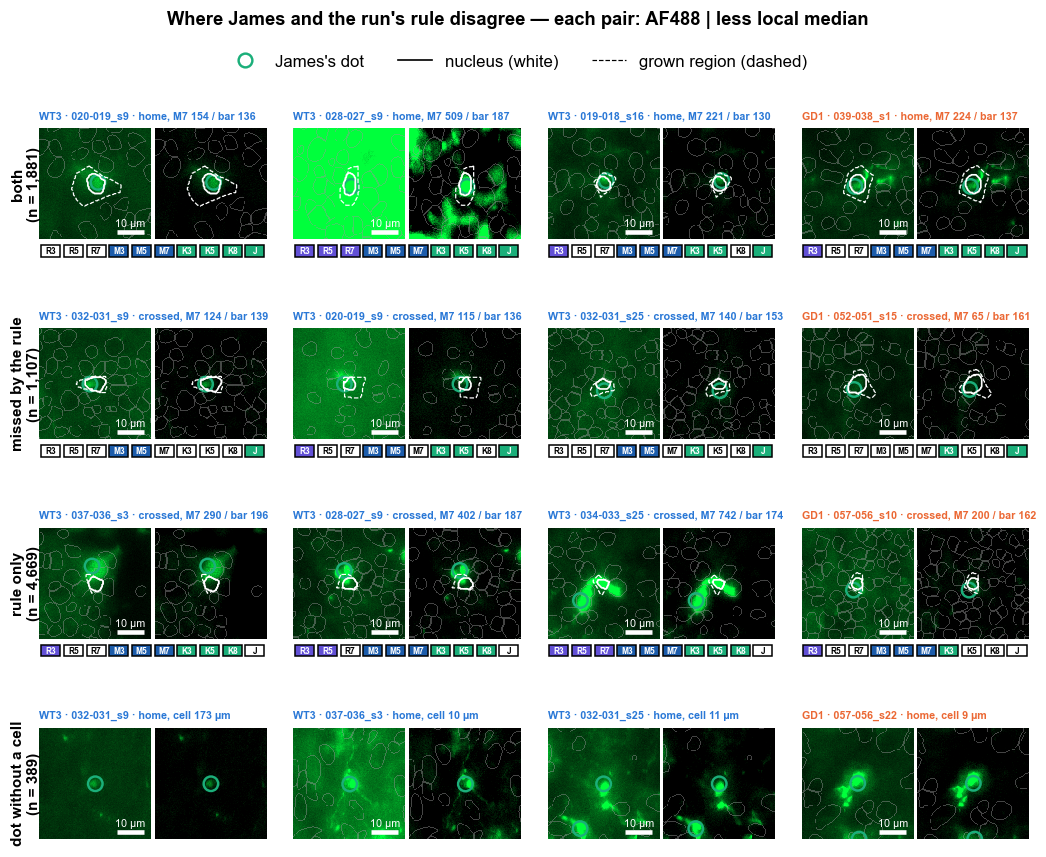

In [16]:
# One figure for slides: a row per kind, N_SUMMARY cells each, AF488 and AF488 less its local median side by side.
fig = plt.figure(figsize=(2.9 * N_SUMMARY, 2.0 * len(chosen) + 0.6))
grid = fig.add_gridspec(len(chosen), N_SUMMARY, hspace=0.55, wspace=0.12)
for i, (kind, rows) in enumerate(chosen.items()):
    for j in range(min(N_SUMMARY, len(rows))):
        row, crop = rows.iloc[j], crops[(kind, j)]
        pair = grid[i, j].subgridspec(1, 2, wspace=0.04)
        left, right = fig.add_subplot(pair[0]), fig.add_subplot(pair[1])
        show_cell(left, crop, row, "raw")
        show_cell(right, crop, row, "filtered", label=False)
        left.set_title(caption(row, kind).replace("\n", " · ", 1), fontsize=7, loc="left",
                       color=GENOTYPE_COLOURS[row["Genotype"]], fontweight="bold", x=0.0)
        if kind != "dot without a cell":
            strip_ax = fig.add_subplot(grid[i, j])
            strip_ax.set_position([left.get_position().x0, left.get_position().y0,
                                   right.get_position().x1 - left.get_position().x0, left.get_position().height])
            strip_ax.axis("off")
            call_strip(strip_ax, row, where=-0.17)
        if j == 0:
            left.text(-0.12, 0.5, f"{kind}\n(n = {len(KINDS[kind]):,})", transform=left.transAxes, rotation=90,
                      ha="center", va="center", fontsize=10, fontweight="bold")
handles = [mpl.lines.Line2D([], [], marker="o", ls="", mfc="none", mec=HAND_COLOUR, mew=1.6, ms=9, label="James's dot"),
           mpl.lines.Line2D([], [], color="black", lw=1.1, label="nucleus (white)"),
           mpl.lines.Line2D([], [], color="black", lw=0.8, ls="--", label="grown region (dashed)")]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.965))
fig.suptitle("Where James and the run's rule disagree — each pair: AF488 | less local median", fontsize=12,
             fontweight="bold", y=0.995)
save(fig, "disagree_summary")
plt.show()

### What the pictures show (4 November 2026, `SEED` 0, 6 cells per kind)

- **Both**: bright, compact cells, a dot on the nucleus, called by nearly every rule. In sections with a bright background (028-027_s9) the raw picture is green all over and only the filtered one shows the cell — why the raw rules call so much there.
- **Rule only is mostly not background.** Half of the 4 669 rule-only cells have one of James's dots within 10 µm (table above). In the pictures, the dot often sits on a bright AF488 body right beside the outlined cell: the labelled cell is counted once by James, and the run's rule also calls a neighbour whose grown region (nucleus + 6 µm) takes in the bright body's light (037-036_s3, 028-027_s9, 038-037_s9). Others are compact, clearly labelled cells with no dot anywhere near (057-056_s22): cells James skipped. The pictures show no evenly hazy background patch called positive. So the rule over-counts **clusters** (one labelled body, several nuclei called), and James under-counts some isolated cells.
- **Missed by the rule: dim cells just under the bar.** Most have a filtered mean of 80–95 % of the run's bar (124 / 139, 115 / 136, 140 / 153) and only a faint spot at the nucleus's edge, often off-centre; M3 / M5 and K3 usually call them. A few are almost black in AF488 (057-056_s22: 41 / 174; 052-051_s15: 65 / 161), with the dot on the edge of a large or odd-shaped nucleus: dots James put on something not visible in this channel's z-maximum, or matched to the wrong nucleus.
- **The bar depends on the section.** The same-looking dim cell is below the bar in one section (038-037_s9, bar 278) and would be above it in another (bar ≈ 140): the bar is set by each junction region's own cells, so a bright region raises it.
- **Dots without a cell** are mostly bright AF488 bodies or processes with **no segmented nucleus** under them (037-036_s3, 032-031_s25, 057-056_s22: nearest cell 9–11 µm away): labelled cells the segmentation (on the nuclear stain) did not find, which no rule can count. A few are outside the segmented tissue altogether (032-031_s9: 173 µm from any cell, a faint speck).
- For the counts: the disagreements are about **where a cell ends** (clusters, spill-over into neighbours, missing nuclei) and **where the bar sits for dim cells**, not about background read as cells. Lowering the run's bar to + 5 SD would bring in about 4 in 10 of James's cells the rule misses (+ 3 SD: 3 in 4), with more rule-only cells too; the cluster over-counting needs objects (the AF488 mask's own objects, 04 section 8c), not a different bar.

## What it showed (4 November 2026: 14 sections, 7 WT3 / 7 GD1 on 11 slides, 3 377 dots)

**Where he counted.** Mostly the home side: 72 % of the dots are on AF488's home side, 5 % in the junction region, 4 % crossed (137 dots; 2–35 per section, one GD1 section, 038-037_s9, has 35 of them). 88 % of the dots have a segmented cell within 7 µm — the ceiling on any rule's recall. Like Quillan's, his dots sit nearer the tissue edge than the average cell (140 against 241 µm).

**Per section.**
- *Whole section:* the median-filter rules and the mask follow him. The run's rule ranks the sections best (Spearman 0.93) at 1.5× his count; the mask's objects at 5 SD match him in rank and number (CCC 0.85, R² 0.88, 0.9× his count). The raw rules do worse (ρ 0.57–0.70).
- *Junction region and crossed:* nothing follows him well (best R² 0.35, mask objects 5 SD; the run's rule ρ 0.69, R² 0.19, about his level, 1.1–1.25×). Far below Quillan's agreement (R² 0.78–0.80, 04 §8d): his crossed counts are small, and one GD1 section where every rule undercounts pulls the fit down. The raw rules: R² 0.00 against both annotators.

**Cell by cell.** The run's rule agrees with him as it did with Quillan: crossed zone precision 0.35, recall 0.45, F1 0.39 (Quillan, validation/09: 0.29 / 0.55 / 0.38); whole section 0.29 / 0.56 / 0.38. The mask at 5 SD is level with it; at 8 SD it is the most precise (0.44–0.47) but finds under 30 % of his dots. F1 never passes 0.39 under any bar: lower bars buy recall with precision.

**Same biology?** (WT3 against GD1; 7 against 7, so only a large difference can show.)
- *More AF488+ cells in WT3:* yes by hand — 1.9× in the whole section (mixed model p 0.008), 2.1× at home (p 0.01). Every rule goes the same way on these 14 (2.6–2.9×).
- *Junction and crossed cells:* the same direction, weaker and not significant by hand (1.2–1.5×), against 2.5–3.5× for the rules on these 14 and on the whole run. His count is consistent with the run's result but too small to confirm it alone.
- *Distance to the edge:* on these 14 sections James **and every rule** put WT3's crossed cells further from the edge (+32 µm by hand, +70 µm the run's rule) — the opposite of the whole run (−70 µm, p 0.001). The 14 sections are not typical on this outcome; they cannot test it.
- *Distance past the line:* the one disagreement — WT3 +26 µm by hand (ns) against −63 µm for the run's rule on the same 14 (p 0.03) and −17 µm on the run; on 6 GD1 sections with ≥ 3 crossed dots.

**Pictures (section 7).** The disagreements are where a cell ends and where the bar sits for dim cells, not background read as cells: rule-only cells are mostly neighbours of a clicked body that its light spills into (half have a dot within 10 µm), or labelled cells he skipped; cells the rule misses are dim, 85–92 % of the bar; dots without a cell are bright bodies with no segmented nucleus.

**Decision.** No change to the run's rule. It is as good against James cell by cell as against Quillan, and his count reproduces the main WT3 > GD1 result. For the per-section number near the line, the mask's objects at 5 SD are worth keeping beside it (they count clusters once). The crossed and edge results stand on the whole run; James's 14 sections are too few and, on the edge outcome, not typical enough to test them.